# Step 1 · Data Profiling (full dataset, before any cleaning)

**Project:** Water Quality DW & Analytics  ·  **Data:** Water Quality Portal (WQP), `resultphyschem.csv`, all **4.96 million rows**

## What is data profiling?
Profiling is a **health check-up of the data before treatment**. A doctor measures first and treats later; we do the same.
Here we only **measure** problems: missing values, duplicates, wrong units, impossible numbers, bad dates, invalid codes, broken coordinates.
**Nothing is changed in this notebook.** The fixes happen in Step 2 (`02_data_curation_imputation.ipynb`), and every fix there points back to a number measured here.

## How to read this notebook
Each section has the same four parts:
1. **What we check / why it matters**, in plain words
2. **Code**, the exact query that was run
3. **Chart or table**, the evidence
4. **🔎 Inference**, what the numbers mean for the project, written from the actual output

## Tools used (simple guide)
| Tool | What it is | Why we use it |
|---|---|---|
| **DuckDB** | A small SQL database engine that runs inside Python | It reads the whole 4.96M-row file without loading it all into the laptop's 7.7 GB of RAM |
| **Parquet** | A compressed, column-based file format | The 2.58 GB CSV becomes 228 MB and reads in seconds; every value is kept as the original text |
| **pandas** | Python's table library | Holds the small result tables |
| **matplotlib / seaborn** | Chart libraries | Draw the evidence charts |

## 0 · Setup
**What this does:** finds the project folder, opens the data with DuckDB, and creates two helpers that save every table (`tables/`) and chart (`figures/`) so they can go into the report and PPT.
If the Parquet copy does not exist yet, it is created once from the CSV; all 81 columns are kept **as text**, exactly as in the source.

In [1]:
import duckdb, pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
pd.set_option('display.max_rows', 120); pd.set_option('display.width', 180); pd.set_option('display.max_colwidth', 70)
sns.set_theme(style='whitegrid', context='notebook')

ROOT = Path.cwd().resolve()
for p in [ROOT, *ROOT.parents]:                     # walk up until the repository root is found
    if (p / 'resultphyschem').exists() or (p / 'data' / 'raw_parquet').exists():
        ROOT = p; break
RAW_CSV = ROOT / 'resultphyschem' / 'resultphyschem.csv'
RAW_PQ  = ROOT / 'data' / 'raw_parquet' / 'wq_raw.parquet'
OUT = ROOT / '01_profiling_curation'
FIG, TAB = OUT / 'figures', OUT / 'tables'
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)

con = duckdb.connect()
con.execute("SET memory_limit='3GB'")
if not RAW_PQ.exists():                              # one-time conversion CSV -> Parquet (all columns as text)
    RAW_PQ.parent.mkdir(parents=True, exist_ok=True)
    con.execute(f"COPY (SELECT * FROM read_csv('{RAW_CSV.as_posix()}', all_varchar=true, header=true, sample_size=-1)) "
                f"TO '{RAW_PQ.as_posix()}' (FORMAT parquet, COMPRESSION zstd)")
con.execute(f"CREATE OR REPLACE VIEW raw AS SELECT * FROM '{RAW_PQ.as_posix()}'")

def q(sql):                       # run SQL, return a pandas table
    return con.execute(sql).df()
def save_tab(df, name, index=False):
    df.to_csv(TAB / f'P{name}.csv', index=index); return df
def save_fig(name):
    plt.tight_layout(); plt.savefig(FIG / f'P{name}.png', dpi=130, bbox_inches='tight'); plt.show()

PARAMS = ['Temperature, water', 'Dissolved oxygen (DO)', 'pH', 'Turbidity', 'Conductivity', 'Nitrate']
SHORT  = {'Temperature, water': 'Temperature', 'Dissolved oxygen (DO)': 'Dissolved oxygen', 'pH': 'pH',
          'Turbidity': 'Turbidity', 'Conductivity': 'Conductivity', 'Nitrate': 'Nitrate'}
print('Repository root :', ROOT)
print('Parquet copy    :', RAW_PQ, f'({RAW_PQ.stat().st_size/1e6:.0f} MB)')

Repository root : L:\0_MITAOE-3rd\SEV- V\EDA\EDA_project
Parquet copy    : L:\0_MITAOE-3rd\SEV- V\EDA\EDA_project\data\raw_parquet\wq_raw.parquet (228 MB)


**Readable column names.** The source uses long names like `ActivityStartTime/Time`. The view below gives them short names for the queries.
It only **renames and reads** columns; the raw text stays untouched (`val_raw`). `TRY_CAST` attempts to read text as a number or date and gives *empty* when it can't, which is exactly how we detect bad values.

In [2]:
con.execute('''
CREATE OR REPLACE VIEW v AS SELECT
  OrganizationIdentifier AS org, ProviderName AS provider, MonitoringLocationIdentifier AS site,
  CharacteristicName AS param, "ResultMeasure/MeasureUnitCode" AS unit,
  ResultMeasureValue AS val_raw, TRY_CAST(ResultMeasureValue AS DOUBLE) AS val,
  ActivityStartDate AS date_raw, TRY_CAST(ActivityStartDate AS DATE) AS dt,
  "ActivityStartTime/Time" AS tm, "ActivityStartTime/TimeZoneCode" AS tz,
  ActivityEndDate AS end_date_raw, "ActivityEndTime/Time" AS end_tm,
  "ActivityLocation/LatitudeMeasure" AS lat_raw, "ActivityLocation/LongitudeMeasure" AS lon_raw,
  TRY_CAST("ActivityLocation/LatitudeMeasure" AS DOUBLE) AS lat,
  TRY_CAST("ActivityLocation/LongitudeMeasure" AS DOUBLE) AS lon,
  ActivityTypeCode AS act_type, ResultStatusIdentifier AS status, ResultValueTypeName AS value_type,
  MeasureQualifierCode AS qualifier, ResultDetectionConditionText AS detect_cond,
  ActivityMediaName AS media, ActivityMediaSubdivisionName AS media_sub, ResultSampleFractionText AS fraction,
  "SampleCollectionMethod/MethodName" AS coll_method, SampleCollectionEquipmentName AS equipment,
  "ActivityDepthHeightMeasure/MeasureValue" AS depth,
  ActivityIdentifier AS act_id, StatisticalBaseCode AS stat, ResultTimeBasisText AS time_basis,
  "ResultDepthHeightMeasure/MeasureValue" AS rdepth,
  (ActivityTypeCode ILIKE '%Logger%' OR ActivityTypeCode ILIKE '%Continuous%' OR ActivityTypeCode ILIKE '%Time Series%') AS is_logger
FROM raw''')
print('view v ready')

view v ready


## 1 · Dataset overview
**What we check:** how big the data is, how many sites, organizations and parameters, and the date range.
**Why it matters:** the brief requires *several sites across multiple states* and *at least two years*. This proves the dataset qualifies, and these are the totals every later step must reconcile back to.

,Value
Rows (results),4958238
Monitoring sites,50476
Organizations,486
Source systems,2
Parameters,6
First date,2024-01-01
Last date,2025-12-31
Months covered,24
Columns in file,81
CSV size (GB),2.59


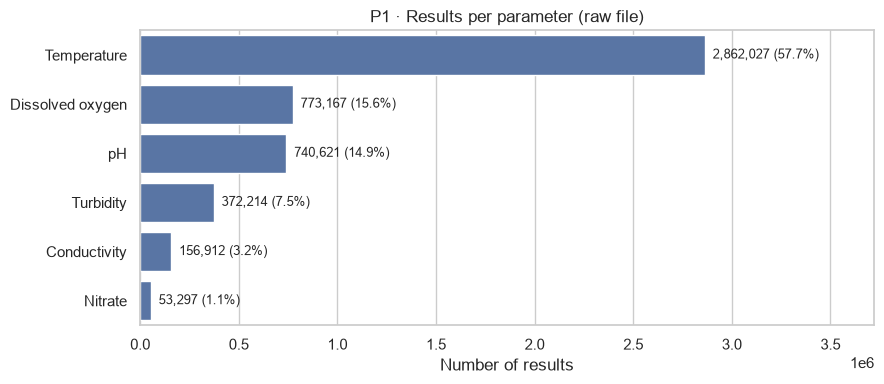

In [3]:
ov = q('''SELECT count(*) AS "Rows (results)", count(DISTINCT site) AS "Monitoring sites",
                 count(DISTINCT org) AS "Organizations", count(DISTINCT provider) AS "Source systems",
                 count(DISTINCT param) AS "Parameters", min(dt)::VARCHAR AS "First date", max(dt)::VARCHAR AS "Last date",
                 count(DISTINCT strftime(dt, '%Y-%m')) AS "Months covered"
          FROM v''').T.rename(columns={0: 'Value'})
ov.loc['Columns in file'] = len(q('DESCRIBE raw'))
if RAW_CSV.exists(): ov.loc['CSV size (GB)'] = round(RAW_CSV.stat().st_size / 1e9, 2)
ov.loc['Parquet size (MB)'] = round(RAW_PQ.stat().st_size / 1e6, 1)
display(save_tab(ov, '01_overview', index=True))

pc = q('SELECT param, count(*) AS n FROM v GROUP BY param ORDER BY n DESC')
pc['pct'] = pc.n / pc.n.sum() * 100
save_tab(pc, '01_rows_per_parameter')
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=pc, y=pc.param.map(SHORT), x='n', color='#4C72B0', ax=ax)
for i, r in pc.reset_index().iterrows():
    ax.text(r.n, i, f'  {r.n:,.0f} ({r.pct:.1f}%)', va='center', fontsize=9)
ax.set(title='P1 · Results per parameter (raw file)', xlabel='Number of results', ylabel='')
ax.set_xlim(0, pc.n.max() * 1.3)
save_fig('01_rows_per_parameter')

**Why this chart:** a sorted bar chart compares the size of each parameter at a glance; the labels give exact counts and shares.

**🔎 Inference (P1): dataset overview**
- The file has **4,958,238 results** from **50,476 sites** and **486 organizations**, covering **1 Jan 2024 – 31 Dec 2025 (all 24 months)**. This meets the brief's requirement of *multiple sites across states and at least two years*.
- **Temperature dominates (57.7%, 2.86M rows)**. Dissolved oxygen (15.6%) and pH (14.9%) follow, and nitrate is only **1.1% (53K rows)**.
- **Impact:**
  - A plain "average of all results" would really be a temperature average, so every later analysis must be **split by parameter**.
  - For nitrate, 53K rows is still enough for analysis, but site-level nitrate statistics will be thinner than for the other parameters.
  - Converting to Parquet shrank 2.59 GB to 228 MB (**11× smaller**), which is why the full file can be profiled on a 7.7 GB laptop.

## 2 · Completeness of all 81 columns
**What we check:** for every column, how many cells are empty (count and %).
**Why it matters:** an empty column cannot be used; a half-empty one needs a decision (fill, flag or ignore). The brief asks for missing counts **and** percentages for all important fields.

,Columns
Band,
0% (complete),11
<5%,9
5–50%,4
50–<100%,52
100% (empty),5


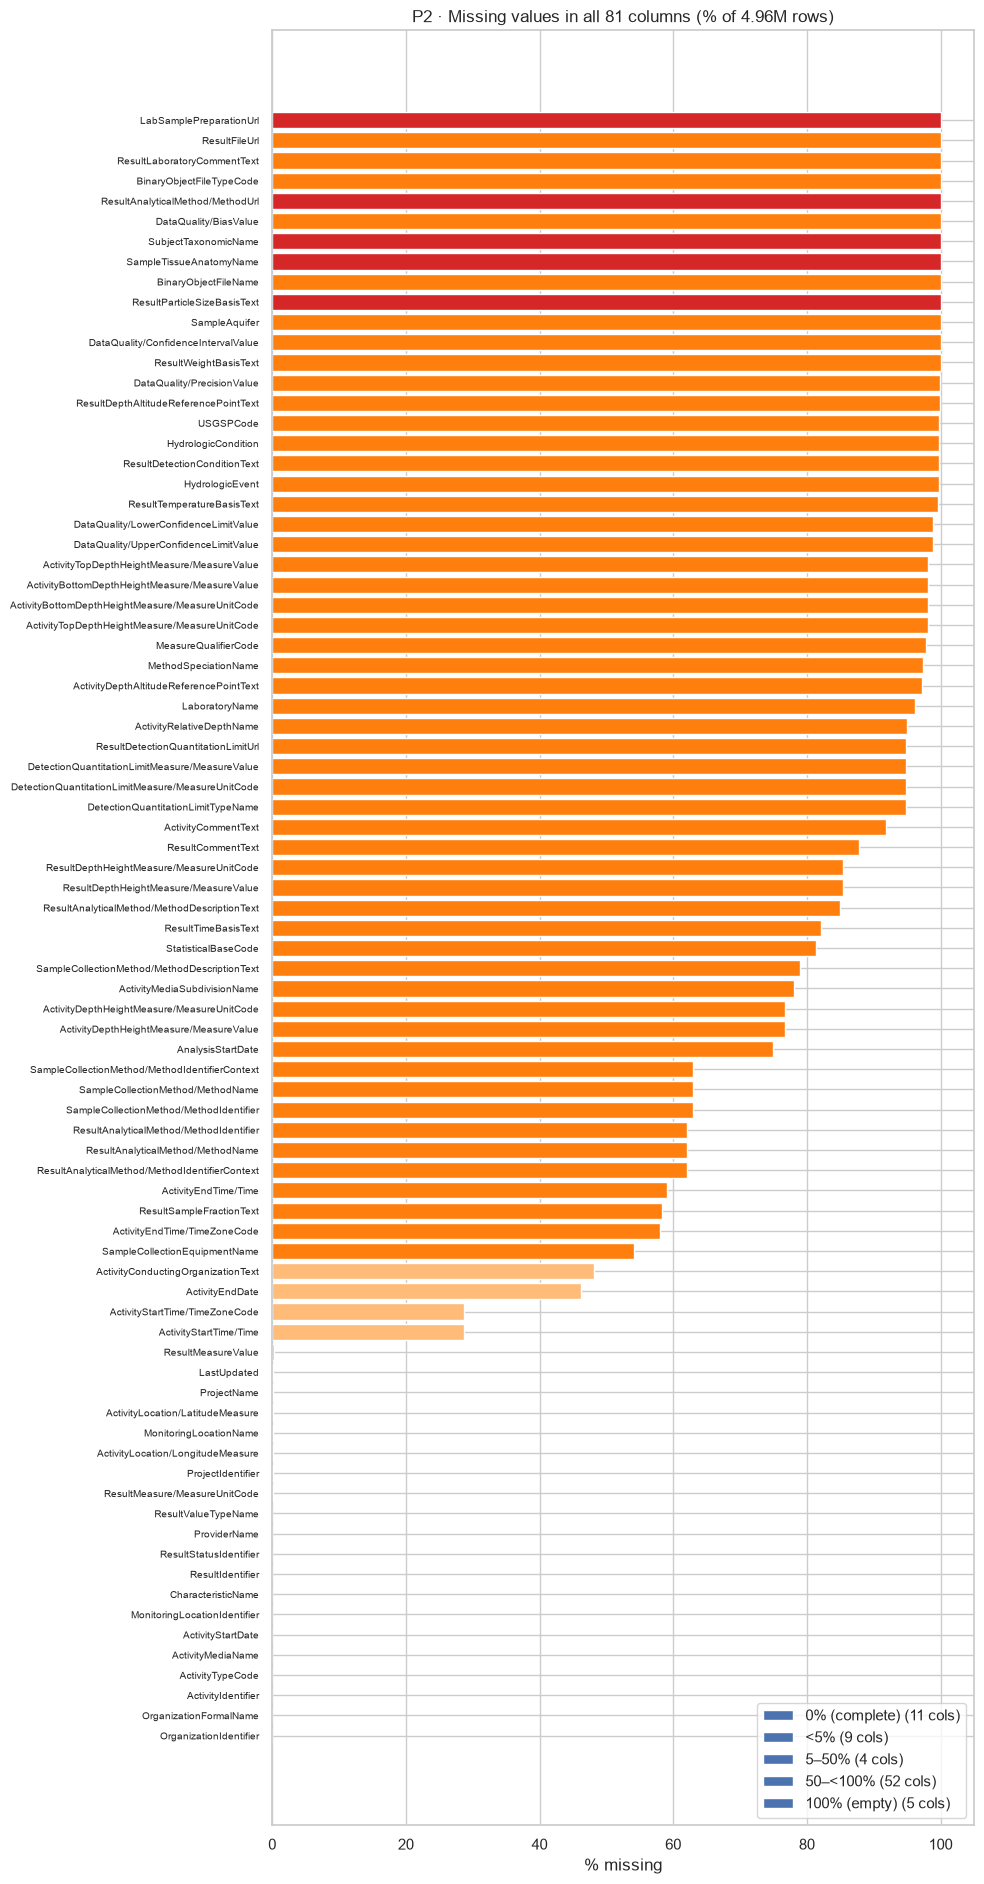

In [4]:
cols = q('DESCRIBE raw')['column_name'].tolist()
nn = q('SELECT count(*) AS __n, ' + ', '.join(f'count("{c}") AS "{c}"' for c in cols) + ' FROM raw').T
N = int(nn.loc['__n', 0]); nn = nn.drop('__n')
miss = pd.DataFrame({'Column': nn.index, 'NonMissing': nn[0].astype(int).values})
miss['Missing'] = N - miss.NonMissing
miss['MissingPct'] = miss.Missing / N * 100
def band(p):
    if p == 0: return '0% (complete)'
    if p < 5: return '<5%'
    if p < 50: return '5–50%'
    return '50–<100%'
miss['Band'] = np.where(miss.Missing == N, '100% (empty)', miss.MissingPct.map(band))
miss['MissingPct'] = miss.MissingPct.round(2)
miss = miss.sort_values('MissingPct')
save_tab(miss, '02_missing_all_columns')
band_order = ['0% (complete)', '<5%', '5–50%', '50–<100%', '100% (empty)']
band_sum = miss.Band.value_counts().reindex(band_order).fillna(0).astype(int).rename('Columns').to_frame()
display(save_tab(band_sum, '02_missing_bands', index=True))

colors = {'0% (complete)': '#2ca02c', '<5%': '#98df8a', '5–50%': '#ffbb78', '50–<100%': '#ff7f0e', '100% (empty)': '#d62728'}
fig, ax = plt.subplots(figsize=(10, 19))
ax.barh(miss.Column, miss.MissingPct, color=miss.Band.map(colors))
ax.set(title='P2 · Missing values in all 81 columns (% of 4.96M rows)', xlabel='% missing', ylabel='')
ax.tick_params(axis='y', labelsize=7.5); ax.set_xlim(0, 105)
for b, c in colors.items(): ax.barh([], [], color=c, label=f'{b} ({band_sum.loc[b, "Columns"]} cols)')
ax.legend(loc='lower right')
save_fig('02_missing_all_columns')

**Why this chart:** one horizontal bar per column, sorted, and coloured by severity band, so the fully empty columns (red) and the nearly complete ones (green) separate visually.

**🔎 Inference (P2): completeness of all 81 columns**
- Only **11 of 81 columns are complete** and another 9 are almost complete (under 5% missing).
- **52 columns are more than half empty**, and **5 are completely empty** (taxonomic name, tissue anatomy, particle-size basis, method URL, lab-preparation URL). These empty columns belong to biological and lab-tissue data, which this physical/chemical extract does not contain.
- **Impact:**
  - The 5 empty columns carry no information and will be **dropped**.
  - The many half-empty columns are mostly optional lab or comment fields that we do not need.
  - The warehouse will therefore use a **small, curated set of columns** (about 25) rather than all 81, which also keeps the warehouse small and fast.

## 3 · Missing values in the **important** fields
**What we check:** the fields the brief lists as *Important Dataset Attributes*, plus the descriptive fields we need for the warehouse dimensions.
**Why it matters:** these feed the warehouse and the models, so each one needs its own justified treatment in Step 2 (the faculty asked for *attribute-specific* decisions, not "all nulls removed").
**Note on pH units:** pH has no unit by definition. In this file the pH unit is mostly the *text* `None`, which is **correct**, not missing. We show the unit gap with and without pH.

,Column,Meaning,Missing,MissingPct
14,ActivityMediaSubdivisionName,Water type (surface/ground…),3869255,78.04
16,ActivityDepthHeightMeasure/MeasureValue,Sampling depth,3801149,76.66
12,SampleCollectionMethod/MethodName,Collection method,3118448,62.89
15,ResultSampleFractionText,Sample fraction,2894690,58.38
13,SampleCollectionEquipmentName,Collection equipment,2681551,54.08
2,ActivityStartTime/Time,Sampling time,1423442,28.71
3,ActivityStartTime/TimeZoneCode,Time zone,1423442,28.71
5,ResultMeasureValue,Measured value,12274,0.25
9,ActivityLocation/LongitudeMeasure,Longitude,8477,0.17
8,ActivityLocation/LatitudeMeasure,Latitude,8477,0.17


Brief attribute 'MonitoringLocationTypeName' present in this file: False


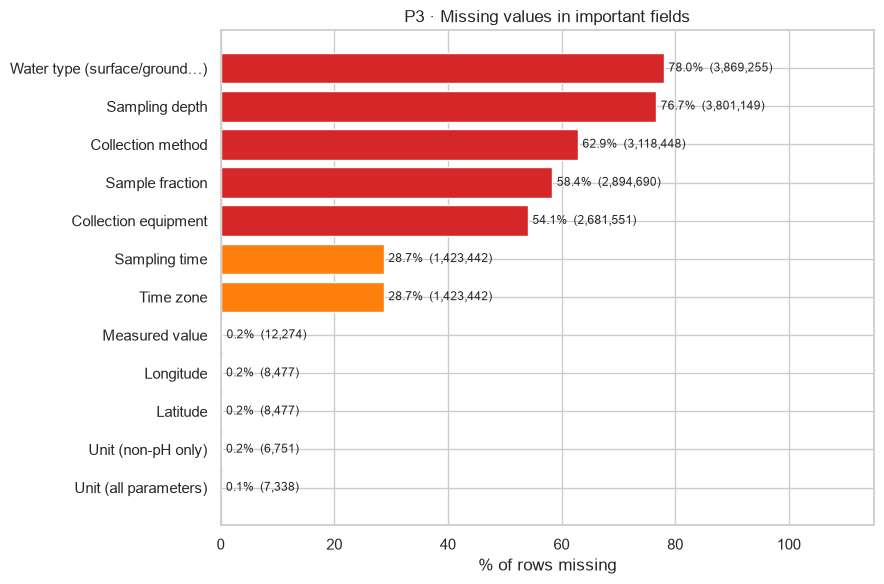

In [5]:
IMPORTANT = {
 'MonitoringLocationIdentifier': 'Monitoring site', 'ActivityStartDate': 'Sampling date',
 'ActivityStartTime/Time': 'Sampling time', 'ActivityStartTime/TimeZoneCode': 'Time zone',
 'CharacteristicName': 'Parameter', 'ResultMeasureValue': 'Measured value',
 'ResultMeasure/MeasureUnitCode': 'Unit (all parameters)', 'OrganizationIdentifier': 'Organization',
 'ActivityLocation/LatitudeMeasure': 'Latitude', 'ActivityLocation/LongitudeMeasure': 'Longitude',
 'ResultStatusIdentifier': 'Result status', 'ActivityTypeCode': 'Activity type',
 'SampleCollectionMethod/MethodName': 'Collection method', 'SampleCollectionEquipmentName': 'Collection equipment',
 'ActivityMediaSubdivisionName': 'Water type (surface/ground…)', 'ResultSampleFractionText': 'Sample fraction',
 'ActivityDepthHeightMeasure/MeasureValue': 'Sampling depth'}
imp = miss.set_index('Column').loc[list(IMPORTANT)].reset_index()
imp.insert(1, 'Meaning', imp.Column.map(IMPORTANT))
unit_np = q("SELECT count(*) n, count(*) FILTER (WHERE unit IS NULL) m FROM v WHERE param <> 'pH'").iloc[0]
imp = pd.concat([imp, pd.DataFrame([{'Column': 'ResultMeasure/MeasureUnitCode (excl. pH)', 'Meaning': 'Unit (non-pH only)',
                 'NonMissing': int(unit_np.n - unit_np.m), 'Missing': int(unit_np.m),
                 'MissingPct': round(unit_np.m / unit_np.n * 100, 2)}])], ignore_index=True)
in_file = 'MonitoringLocationTypeName' in cols
imp = imp.sort_values('MissingPct', ascending=False)
display(save_tab(imp[['Column', 'Meaning', 'Missing', 'MissingPct']], '03_missing_important'))
print("Brief attribute 'MonitoringLocationTypeName' present in this file:", in_file)

fig, ax = plt.subplots(figsize=(9, 6))
d = imp[imp.MissingPct > 0]
bars = ax.barh(d.Meaning, d.MissingPct, color=['#d62728' if p >= 50 else '#ff7f0e' if p >= 5 else '#98df8a' for p in d.MissingPct])
for b, (p, m) in zip(bars, zip(d.MissingPct, d.Missing)):
    ax.text(b.get_width() + 0.8, b.get_y() + b.get_height() / 2, f'{p:.1f}%  ({m:,.0f})', va='center', fontsize=8.5)
ax.invert_yaxis(); ax.set_xlim(0, 115)
ax.set(title='P3 · Missing values in important fields', xlabel='% of rows missing', ylabel='')
save_fig('03_missing_important')

**Why this chart:** only the important fields that have gaps, labelled with both % and count, because the brief asks for both.

**🔎 Inference (P3): important fields**
- **All core identifiers are complete (0% missing):** site, date, parameter, organization, status, activity type. Every result can be placed in time, space and parameter, so the warehouse's main dimensions have no gaps.
- **The measured value is missing in only 0.25% (12,274 rows)**, and the unit (excluding pH) in only 0.16%.
- **Coordinates are missing in 0.17% (8,477 rows).**
- **Large gaps are only in descriptive fields:**
  - water type 78%
  - sampling depth 77%
  - collection method 63%
  - sample fraction 58%
  - equipment 54%
  - **time of day 28.7% (1.42M rows)**
- The brief's attribute *MonitoringLocationTypeName* (site type) is **not in this file**. It must come from the WQP *Station* file or be derived (for example from the water-type field).
- **Impact:** the gaps sit in *descriptive* columns, not in the measurements. So we do **not** need to drop rows; we need a strategy to **fill descriptive labels** (rule-based, Decision Tree or Naive Bayes) and to mark the rest *Not Reported*.

## 4 · Is missingness random or does it follow a pattern? (by parameter)
**What we check:** the % missing of each descriptive field, separately for each parameter.
**Why it matters:** this decides **how** we can fill gaps. If a value is missing **at random**, the best we can do is the most common value. If missingness follows a **pattern** (it depends on other columns), a model such as a **Decision Tree** or **Naive Bayes** can learn that pattern and predict the missing label. That is the justification the faculty asked for.

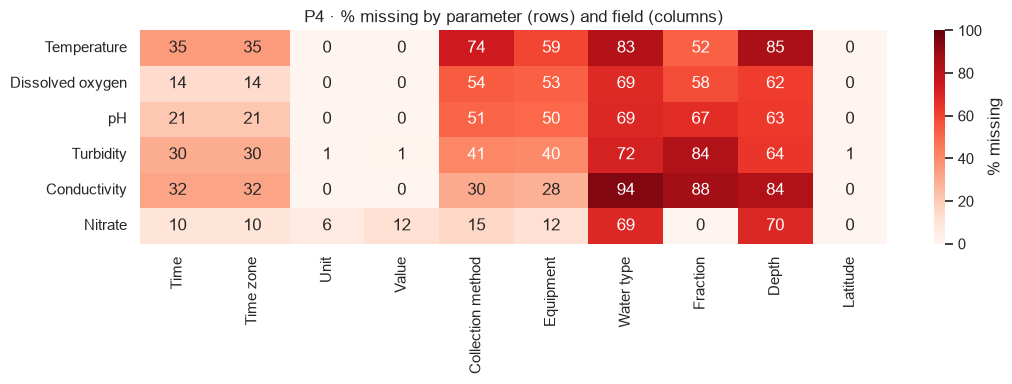

In [6]:
FIELDS = {'Time': 'tm', 'Time zone': 'tz', 'Unit': 'unit', 'Value': 'val_raw', 'Collection method': 'coll_method',
          'Equipment': 'equipment', 'Water type': 'media_sub', 'Fraction': 'fraction', 'Depth': 'depth', 'Latitude': 'lat_raw'}
sel = ', '.join(f'avg(CASE WHEN ({c}) IS NULL THEN 100.0 ELSE 0 END) AS "{k}"' for k, c in FIELDS.items())
mp = q(f'SELECT param, {sel} FROM v GROUP BY param').set_index('param').loc[PARAMS]
mp.index = mp.index.map(SHORT)
save_tab(mp.round(1), '04_missing_by_parameter', index=True)
fig, ax = plt.subplots(figsize=(11, 4))
sns.heatmap(mp, annot=True, fmt='.0f', cmap='Reds', vmin=0, vmax=100, cbar_kws={'label': '% missing'}, ax=ax)
ax.set(title='P4 · % missing by parameter (rows) and field (columns)', xlabel='', ylabel='')
save_fig('04_missing_by_parameter')

**Why this chart:** a heat map puts 60 percentages in one picture; dark cells show where data is missing, and uneven colour down a column means missingness depends on the parameter (a pattern).

**🔎 Inference (P4): missingness by parameter**
- Missingness is **not uniform**:
  - Time of day is missing for **34.7% of temperature** rows but only **10% of nitrate** rows.
  - Sample fraction is missing for 88% of conductivity but **0% of nitrate**.
  - Water type is missing for 94% of conductivity vs 69% of DO.
- The measured value itself is almost always present, **except nitrate (12.4% missing)**, mostly *non-detects* where the value was below what the lab could measure.
- **Impact:**
  - Because missingness changes with the parameter, it is **not completely random**. The parameter is an informative input for predicting missing labels.
  - For nitrate, the missing values are mostly *below detection*, which is real information ("very low") rather than missing data, and must be kept as *censored / non-detect* rather than treated as unknown.

## 5 · Missingness by organization (the strongest pattern)
**What we check:** for the 15 largest organizations, how often each descriptive field is missing. We also measure the share of rows whose organization **always** or **never** fills a field.
**Why it matters:** if missingness is decided mainly by *who collected the data*, then organization (plus site, parameter and activity type) can predict the missing label. Those become the input features for the Decision Tree and Naive Bayes imputation in Step 2.

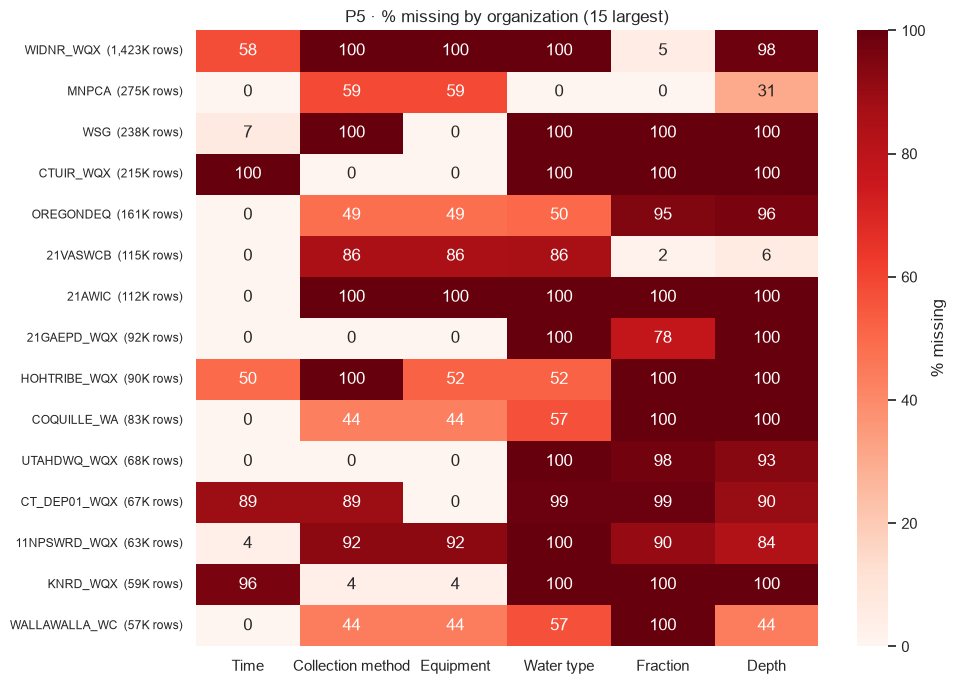

,Field,% rows in orgs that ALWAYS or NEVER fill it,% rows in orgs that fill it only sometimes
0,Time,54.8,45.2
1,Collection method,41.4,58.6
2,Equipment,40.5,59.5
3,Water type,81.9,18.1
4,Fraction,44.3,55.7
5,Depth,42.4,57.6


In [7]:
top_orgs = q('SELECT org, count(*) n FROM v GROUP BY org ORDER BY n DESC LIMIT 15')
F5 = {k: FIELDS[k] for k in ['Time', 'Collection method', 'Equipment', 'Water type', 'Fraction', 'Depth']}
sel = ', '.join(f'avg(CASE WHEN ({c}) IS NULL THEN 100.0 ELSE 0 END) AS "{k}"' for k, c in F5.items())
mo = q(f"SELECT org, count(*) AS rows, {sel} FROM v WHERE org IN ({', '.join(repr(o) for o in top_orgs.org)}) GROUP BY org ORDER BY rows DESC").set_index('org')
save_tab(mo.round(1), '05_missing_by_top_orgs', index=True)
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(mo.drop(columns='rows'), annot=True, fmt='.0f', cmap='Reds', vmin=0, vmax=100, cbar_kws={'label': '% missing'}, ax=ax)
ax.set_yticklabels([f'{o}  ({n/1e3:,.0f}K rows)' for o, n in mo.rows.items()], rotation=0, fontsize=8.5)
ax.set(title='P5 · % missing by organization (15 largest)', xlabel='', ylabel='')
save_fig('05_missing_by_top_orgs')

rows = []
for k, c in F5.items():
    r = q(f'''WITH o AS (SELECT org, count(*) n, avg(CASE WHEN ({c}) IS NULL THEN 1.0 ELSE 0 END) rate FROM v GROUP BY org)
              SELECT sum(n) FILTER (WHERE rate = 0 OR rate = 1) / sum(n) * 100 AS all_or_nothing,
                     sum(n) FILTER (WHERE rate > 0 AND rate < 1) / sum(n) * 100 AS mixed FROM o''').iloc[0]
    rows.append({'Field': k, '% rows in orgs that ALWAYS or NEVER fill it': round(r.all_or_nothing, 1),
                 '% rows in orgs that fill it only sometimes': round(r.mixed, 1)})
aon = pd.DataFrame(rows)
display(save_tab(aon, '05_org_all_or_nothing'))

**Why this chart:** a heat map of organizations × fields shows whether gaps come from particular organizations (solid dark rows) or are scattered (patchy). The table puts a number on it.

**🔎 Inference (P5): missingness by organization (key finding for imputation)**
- The heat map shows **solid rows of 0% and 100%**: missingness is decided mainly by **who collected the data**. For example:
  - **CTUIR_WQX never records time** (100% missing).
  - **WIDNR_WQX**, the largest organization with **1.42M rows (29% of all data)**, never records collection method, equipment or water type.
  - **MNPCA always records water type and fraction.**
- For **water type, 81.9%** of rows come from organizations that *always or never* fill it. For the other fields it is **40–55%**.
- **Impact (justification for model-based imputation):**
  - Because missingness is strongly tied to organization and the other fields, it is **Missing At Random (MAR)**, not completely random. A **Decision Tree** or **Naive Bayes** can learn "this kind of organization/site/activity usually has value X" and predict missing labels better than filling with the most common value.
  - Where an organization *never* records a field, there is nothing inside that organization to learn from, so the model must rely on *other* rows (similar sites and activities). Step 2 measures whether the prediction is accurate enough before using it; otherwise the value stays **Not Reported**.

## 6 · Duplicates (three different kinds)
**What we check:**
- **Exact duplicate:** a row identical in all 81 columns (the same record loaded twice).
- **Repeated result ID:** the same `ResultIdentifier` used twice.
- **Same value repeated inside one activity:** the same sampling activity, parameter, fraction, statistic, depths (activity depth **and** result depth), value and unit appear more than once. In a **single field visit** this is a likely duplicate. In an **automatic logger** activity, many readings share one activity ID and the reading time is not stored per result, so equal values are expected and are **not** duplicates.
- **Same-value repeat from different activities:** different sampling activities at the same site, date and time with the same value. When the **time of day is missing**, these are usually separate logger readings taken on the same day, so they are **not** duplicates.
- **Conflicting repeat:** in **field visits** (not loggers), the same site, date, time, parameter, fraction, depths and statistic, but **different values**: usually replicate readings taken during one visit.

**Why it matters:** true duplicates double-count results. But wrongly calling separate readings "duplicates" would delete real data, so each kind gets its own treatment. The brief asks for exact and logical duplicates to be identified **separately**.

,Check,Rows,% of rows
0,Exact duplicate (all 81 columns identical),0,0.000
1,Repeated ResultIdentifier,0,0.000
2,Same value repeated inside one FIELD-VISIT activity (likely duplic...,186497,3.761
3,Same value repeated inside one LOGGER activity (separate readings),78570,1.585
4,"Same-value repeat, different activities, time known",454629,9.169
5,"Same-value repeat, different activities, time MISSING (likely sepa...",373617,7.535
6,"Conflicting repeat in field visits: same key, different value (row...",559272,11.280


Organizations behind same-value repeats without time:


,org,extra
0,WIDNR_WQX,365878.0
1,TCEQMAIN,5414.0
2,CTUIR_WQX,1057.0
3,RPI,621.0
4,MDNR,432.0


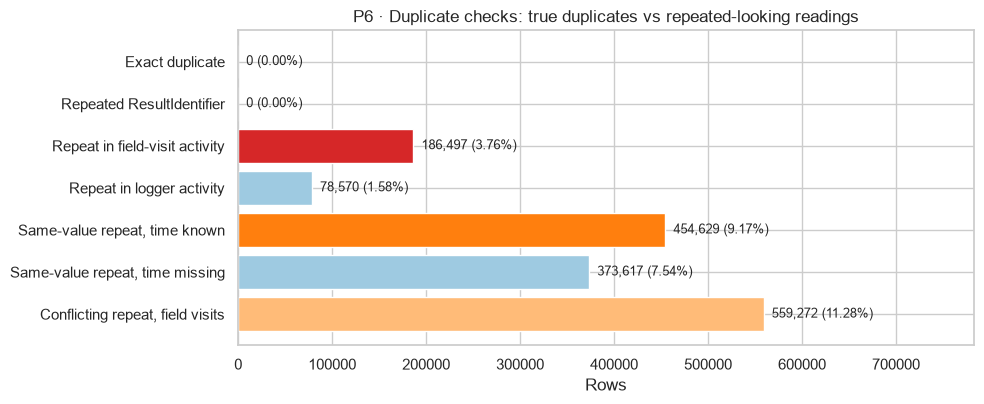

In [8]:
exact = q('SELECT count(*) - count(DISTINCT hash(*COLUMNS(*))) AS n FROM raw').n[0]
rid = q('SELECT count(*) - count(DISTINCT ResultIdentifier) AS n FROM raw').n[0]
same_act = q('''WITH g AS (SELECT act_id, param, fraction, stat, depth, rdepth, val_raw, unit, count(*) c, bool_or(is_logger) logger
                           FROM v GROUP BY act_id, param, fraction, stat, depth, rdepth, val_raw, unit HAVING count(*) > 1)
                SELECT logger, count(*) AS n_groups, coalesce(sum(c - 1), 0) AS extra FROM g GROUP BY logger''')
sa_disc = int(same_act.loc[~same_act.logger, 'extra'].sum()); sa_log = int(same_act.loc[same_act.logger, 'extra'].sum())
rep = q('''WITH g AS (SELECT site, date_raw, tm, param, fraction, depth, rdepth, stat, val_raw, unit, count(*) c,
                            any_value(tm IS NULL) no_time
                     FROM v GROUP BY site, date_raw, tm, param, fraction, depth, rdepth, stat, val_raw, unit
                     HAVING count(*) > 1 AND count(DISTINCT act_id) > 1)
           SELECT no_time, sum(c - 1) AS extra FROM g GROUP BY no_time''')
rep_t = int(rep.loc[~rep.no_time, 'extra'].sum()); rep_nt = int(rep.loc[rep.no_time, 'extra'].sum())
conflict = q('''WITH g AS (SELECT site, date_raw, tm, param, fraction, depth, rdepth, stat, count(*) c FROM v
                           WHERE tm IS NOT NULL AND NOT is_logger GROUP BY ALL HAVING count(*) > 1 AND count(DISTINCT val_raw) > 1)
                SELECT count(*) AS n_groups, coalesce(sum(c), 0) AS n_rows FROM g''').iloc[0]
rep_org = q('''WITH g AS (SELECT site, date_raw, tm, param, fraction, depth, rdepth, stat, val_raw, unit, count(*) c, any_value(org) org
                          FROM v WHERE tm IS NULL GROUP BY site, date_raw, tm, param, fraction, depth, rdepth, stat, val_raw, unit
                          HAVING count(*) > 1 AND count(DISTINCT act_id) > 1)
               SELECT org, sum(c - 1) AS extra FROM g GROUP BY org ORDER BY extra DESC LIMIT 5''')
dup = pd.DataFrame([
  ['Exact duplicate (all 81 columns identical)', int(exact)],
  ['Repeated ResultIdentifier', int(rid)],
  ['Same value repeated inside one FIELD-VISIT activity (likely duplicate)', sa_disc],
  ['Same value repeated inside one LOGGER activity (separate readings)', sa_log],
  ['Same-value repeat, different activities, time known', rep_t],
  ['Same-value repeat, different activities, time MISSING (likely separate readings)', rep_nt],
  ['Conflicting repeat in field visits: same key, different value (rows involved)', int(conflict.n_rows)]],
  columns=['Check', 'Rows'])
dup['% of rows'] = (dup.Rows / N * 100).round(3)
display(save_tab(dup, '06_duplicates'))
print('Organizations behind same-value repeats without time:'); display(save_tab(rep_org, '06_repeats_no_time_by_org'))

fig, ax = plt.subplots(figsize=(10, 4.2))
lab = ['Exact duplicate', 'Repeated ResultIdentifier', 'Repeat in field-visit activity', 'Repeat in logger activity',
       'Same-value repeat, time known', 'Same-value repeat, time missing', 'Conflicting repeat, field visits']
bars = ax.barh(lab, dup.Rows, color=['#2ca02c', '#2ca02c', '#d62728', '#9ecae1', '#ff7f0e', '#9ecae1', '#ffbb78'])
for b_, n_, p_ in zip(bars, dup.Rows, dup['% of rows']):
    ax.text(b_.get_width(), b_.get_y() + b_.get_height() / 2, f'  {n_:,.0f} ({p_:.2f}%)', va='center', fontsize=9)
ax.invert_yaxis(); ax.set_xlim(0, max(dup.Rows.max() * 1.4, 1))
ax.set(title='P6 · Duplicate checks: true duplicates vs repeated-looking readings', xlabel='Rows', ylabel='')
save_fig('06_duplicates')

**Why this chart:** each duplicate kind gets its own bar and colour, so the true problem (red) is not confused with readings that only *look* repeated (blue/orange).

**🔎 Inference (P6): duplicates**
- **No exact duplicates (0)** and **no repeated ResultIdentifier (0)**: no record was loaded twice, and every row has a unique source ID.
- **Separating "looks repeated" from "is repeated" was essential.** A naive check (same site, date, time, parameter and value) first flagged **25.9%** of the data as duplicates. Inspection showed most are **not**:
  - **Logger activities (78,570 extra rows):** many readings share one activity ID with no per-reading time. These are separate readings.
  - **Same value, different activities, time missing (373,617):** **WIDNR_WQX** alone accounts for **380K** of these. Its temperature loggers report several readings per day without the time, so equal values on the same day are expected.
  - **Field-visit activities with the same value repeated (186,497; 3.8%):** the **likely real duplicates**. They will be flagged, with only one copy used in analysis.
  - **Conflicting repeats in field visits (559,272 rows, 11.3%):** same site, time and depth with *different* values, typically replicate readings in one visit. Both are kept and averaged per visit for site-level analysis.
- **Impact:** blindly removing "duplicates" would have deleted about a quarter of the data, mostly real logger readings. Instead, duplicates are **flagged by type**, and the warehouse grain uses `ResultIdentifier` as the unique source key.

## 6b · Mixed grain: single readings vs daily summaries
**What we check:** the `StatisticalBaseCode` field. When it is filled, the row is **not one measurement** but a **summary** of many (daily mean, daily minimum, daily maximum, 7-day average daily maximum "7DADM").
**Why it matters:** the brief's grain rule says *one fact row = one measured result*, and *a fact table must not mix different grains*. Averaging a daily **maximum** together with single readings would give wrong answers, so summary rows must be separated.

,grain,statistic,time_basis,n,pct
0,Single reading,-,(blank),4036135,81.40
1,Summary statistic,Mean,1 Day,237732,4.79
2,Summary statistic,Maximum,1 Day,119219,2.40
3,Summary statistic,Minimum,1 Day,119218,2.40
4,Summary statistic,7DADM,7 Day,79872,1.61
5,Summary statistic,Mean,24 Hours,76417,1.54
6,Summary statistic,Minimum,24 Hours,76417,1.54
7,Summary statistic,Maximum,24 Hours,76417,1.54
8,Summary statistic,Daily Minimum,1 Day,18471,0.37
9,Summary statistic,Daily Maximum,1 Day,18471,0.37


Summary-statistic rows: 921,023 (18.6%) from 52 organizations


,org,n
0,OREGONDEQ,131262
1,HOHTRIBE_WQX,87588
2,COQUILLE_WA,82657
3,CTUIR_WQX,75129
4,CT_DEP01_WQX,59338
5,KNRD_WQX,56648
6,WALLAWALLA_WC,56291
7,PUR_WQX,41007


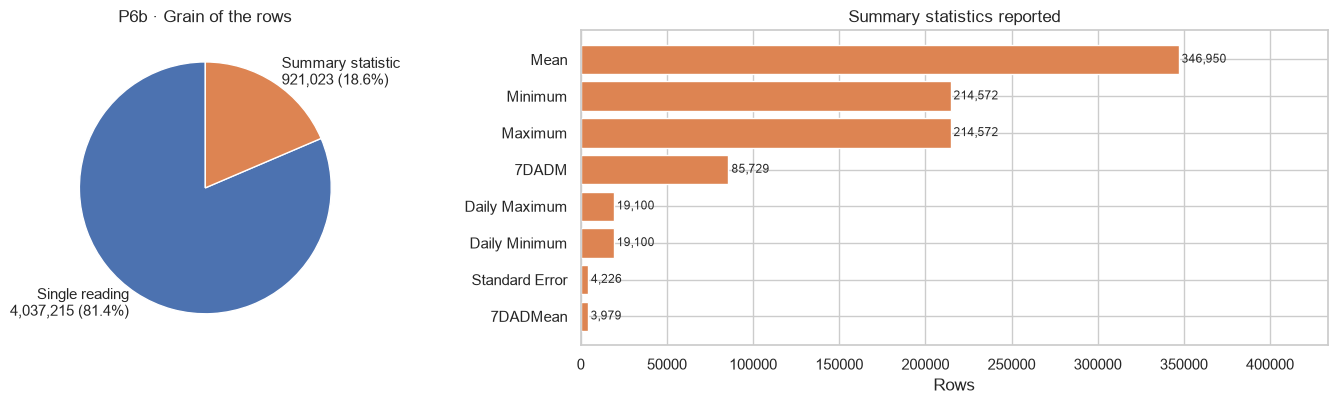

In [9]:
gr = q('''SELECT CASE WHEN stat IS NULL THEN 'Single reading' ELSE 'Summary statistic' END AS grain,
                 coalesce(stat, '-') AS statistic, coalesce(time_basis, '(blank)') AS time_basis, count(*) n
          FROM v GROUP BY ALL ORDER BY n DESC''')
gr['pct'] = (gr.n / N * 100).round(2)
display(save_tab(gr.head(15), '06b_statistic_codes'))
gsum = gr.groupby('grain').n.sum()
summary_rows = int(gsum.get('Summary statistic', 0))
gorg = q("SELECT org, count(*) n FROM v WHERE stat IS NOT NULL GROUP BY org ORDER BY n DESC LIMIT 8")
print(f'Summary-statistic rows: {summary_rows:,} ({summary_rows / N * 100:.1f}%) from',
      q('SELECT count(DISTINCT org) n FROM v WHERE stat IS NOT NULL').n[0], 'organizations')
display(save_tab(gorg, '06b_summary_rows_by_org'))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={'width_ratios': [1, 1.6]})
axes[0].pie(gsum, labels=[f'{k}\n{v:,} ({v / N * 100:.1f}%)' for k, v in gsum.items()], colors=['#4C72B0', '#DD8452'], startangle=90)
axes[0].set(title='P6b · Grain of the rows')
top = gr[gr.grain == 'Summary statistic'].groupby('statistic').n.sum().sort_values().tail(8)
axes[1].barh(top.index, top.values, color='#DD8452')
for i, v_ in enumerate(top.values): axes[1].text(v_, i, f' {v_:,}', va='center', fontsize=8.5)
axes[1].set(title='Summary statistics reported', xlabel='Rows'); axes[1].set_xlim(right=top.max() * 1.25)
save_fig('06b_mixed_grain')

**Why this chart:** the pie shows how much of the file is a different grain; the bar chart shows which summary types make up that share.

**🔎 Inference (P6b): mixed grain (single readings vs daily summaries)**
- **921,023 rows (18.6%) are not single measurements** but **summary statistics** from **52 organizations**: daily mean (4.8%), daily maximum/minimum (2.4% each), 24-hour mean/min/max, and the **7-day average daily maximum (7DADM, 1.6%)**, a temperature metric used for fish-habitat standards.
- The largest suppliers of summary rows are **OREGONDEQ (131K)**, **HOHTRIBE_WQX (88K)**, **COQUILLE_WA (83K)** and **CTUIR_WQX (75K)**.
- **Impact (important for the warehouse design):**
  - The brief says *one fact row = one measured result* and that a fact table *must not mix grains*. Mixing a "daily maximum" with single readings would push averages up, and the same day would be counted 3 times (mean, min and max).
  - So summary rows get a **`StatisticType`** attribute and are kept **separate** from single readings, either filtered out of the main fact or placed in their own summary fact. This is a strong example of profiling changing the dimensional model.

## 7 · Can the measured value be read as a number?
**What we check:** each `ResultMeasureValue` is sorted into one of these groups:
- **Numeric:** a proper number
- **'=' prefix:** like `=7.2`, a formatting slip that can be fixed
- **Censored:** like `<0.5`, only a limit (below detection), not an exact value
- **Text placeholder:** like `Null` or `Not Reported`
- **Missing:** empty, sometimes with a *non-detect* note

**Why it matters:** only real numbers can be averaged or used in models; every other group needs its own rule in Step 2.

kind,Censored (< or >),Equals-sign prefix (fixable),Missing (non-detect noted),Numeric,Text placeholder,Total,% not numeric
param,,,,,,,
Temperature,6.0,0.0,657.0,2843927.0,17437.0,2862027.0,0.63
Dissolved oxygen,40.0,0.0,838.0,771358.0,931.0,773167.0,0.23
pH,7.0,4952.0,907.0,732829.0,1926.0,740621.0,1.05
Turbidity,1023.0,4756.0,3138.0,362125.0,1172.0,372214.0,2.71
Conductivity,23.0,0.0,116.0,156135.0,638.0,156912.0,0.50
Nitrate,180.0,0.0,6618.0,46318.0,181.0,53297.0,13.09


Most common text placeholders:


,text_value,n
0,NA,19554
1,Null,773
2,Not Reported,481
3,NF,441
4,na,207
5,NO DATA,163
6,N/A,120
7,ND,102
8,mdp,78
9,Not recorded,52


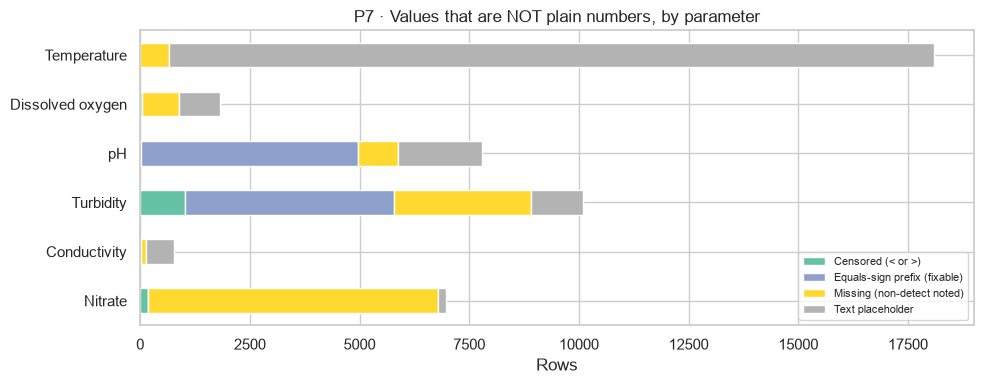

In [10]:
vk = q(r'''SELECT param,
             CASE WHEN val_raw IS NULL THEN CASE WHEN detect_cond IS NOT NULL THEN 'Missing (non-detect noted)' ELSE 'Missing' END
                  WHEN val IS NOT NULL THEN 'Numeric'
                  WHEN regexp_matches(trim(val_raw), '^=\s*-?[0-9.]+$') THEN 'Equals-sign prefix (fixable)'
                  WHEN regexp_matches(trim(val_raw), '^[<>]') THEN 'Censored (< or >)'
                  ELSE 'Text placeholder' END AS kind, count(*) n
           FROM v GROUP BY ALL''')
vt = vk.pivot_table(index='param', columns='kind', values='n', fill_value=0).loc[PARAMS]
vt.index = vt.index.map(SHORT)
vt['Total'] = vt.sum(axis=1); vt['% not numeric'] = ((1 - vt['Numeric'] / vt.Total) * 100).round(2)
display(save_tab(vt, '07_value_parseability', index=True))
txt = q(r'''SELECT trim(val_raw) AS text_value, count(*) n FROM v
            WHERE val_raw IS NOT NULL AND val IS NULL AND NOT regexp_matches(trim(val_raw), '^(=\s*-?[0-9.]+|[<>].*)$')
            GROUP BY 1 ORDER BY n DESC LIMIT 12''')
print('Most common text placeholders:'); display(save_tab(txt, '07_text_placeholders'))

nonnum = vt.drop(columns=['Numeric', 'Total', '% not numeric'])
ax = nonnum.plot(kind='barh', stacked=True, figsize=(10, 4), colormap='Set2')
ax.set(title='P7 · Values that are NOT plain numbers, by parameter', xlabel='Rows', ylabel='')
ax.invert_yaxis(); ax.legend(fontsize=8, loc='lower right')
save_fig('07_value_parseability')

**Why this chart:** numeric rows are about 99% of the data and would hide everything else, so the stacked bar shows **only the problem groups**, split by type.

**🔎 Inference (P7): can the value be read as a number?**
- **99.0% of values are clean numbers.** Of the rest:
  - **22,285 text placeholders** such as `NA` (19,554), `Null`, `Not Reported` and `NF`: no measurement inside, so excluded from numeric analysis.
  - **9,708 values with an "=" prefix** (pH 4,952, turbidity 4,756): the number is fine, so we **strip the "="** and keep them.
  - **1,279 censored values** like `<0.5`: only a limit; flagged and the limit stored separately.
  - **12,274 empty values**, and **every one of them carries a detection-condition note** (for example *Not Detected*), mostly nitrate (6,618). So an empty value here means "too low to measure", not "unknown".
- **Nitrate is the most affected parameter (13.1% not numeric)**, mostly because concentrations are often below the lab's detection limit.
- **Impact:**
  - Fixing the "=" prefix rescues about 10K valid measurements.
  - Nitrate non-detects are kept as their own category ("below detection") so the nitrate picture is not biased toward high values.

## 8 · Units: is each parameter measured in one unit?
**What we check:** which units each parameter is reported in, and how often.
**Why it matters:** you cannot average 20 °C with 68 °F. Mixed units must be converted to **one standard unit per parameter** before analysis; units that cannot be converted (e.g. pH in millivolts) must be excluded from numeric analysis.

Units per parameter (top 4 + Other):


unit_g,%,(blank),Deg,FNU,FTU,JTU,Mole/L,NTU,None,Other,...,mS/cm,mV,mg/L,ms,ppm,std units,uS/cm,ueq/L,ug/L,umho/cm
param,,,,,,,,,,,,,,,,,,,,,
"Temperature, water",0.00,0.02,0.06,0.00,0.00,0.0,0.00,0.00,0.0,0.03,...,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00
Dissolved oxygen (DO),1.17,0.09,0.00,0.00,0.00,0.0,0.00,0.00,0.0,0.00,...,0.00,0.00,98.06,0.00,0.68,0.0,0.00,0.00,0.00,0.00
pH,0.00,0.00,0.00,0.00,0.00,0.0,0.09,0.00,95.6,0.18,...,0.00,3.73,0.00,0.00,0.00,0.4,0.00,0.00,0.00,0.00
Turbidity,0.00,0.00,0.00,27.67,2.15,1.2,0.00,67.25,0.0,1.73,...,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00
Conductivity,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.0,0.24,...,8.95,0.00,0.00,0.78,0.00,0.0,61.71,0.00,0.00,28.32
Nitrate,0.00,6.40,0.00,0.00,0.00,0.0,0.00,0.00,0.0,3.40,...,0.00,0.00,85.95,0.00,0.00,0.0,0.00,2.08,2.17,0.00


Distinct units per parameter:


param
Temperature, water       12
Dissolved oxygen (DO)     9
pH                       18
Turbidity                12
Conductivity              9
Nitrate                  11
Name: distinct units, dtype: int64

Unit status (rows):


status,Convertible (formula),Different measure (% saturation),Standard / equivalent,Unusable / invalid
param,,,,
Temperature,885447,0,1973589,2991
Dissolved oxygen,0,9074,763408,685
pH,0,0,711572,29049
Turbidity,0,0,368116,4098
Conductivity,14270,0,141271,1371
Nitrate,2825,0,46185,4287


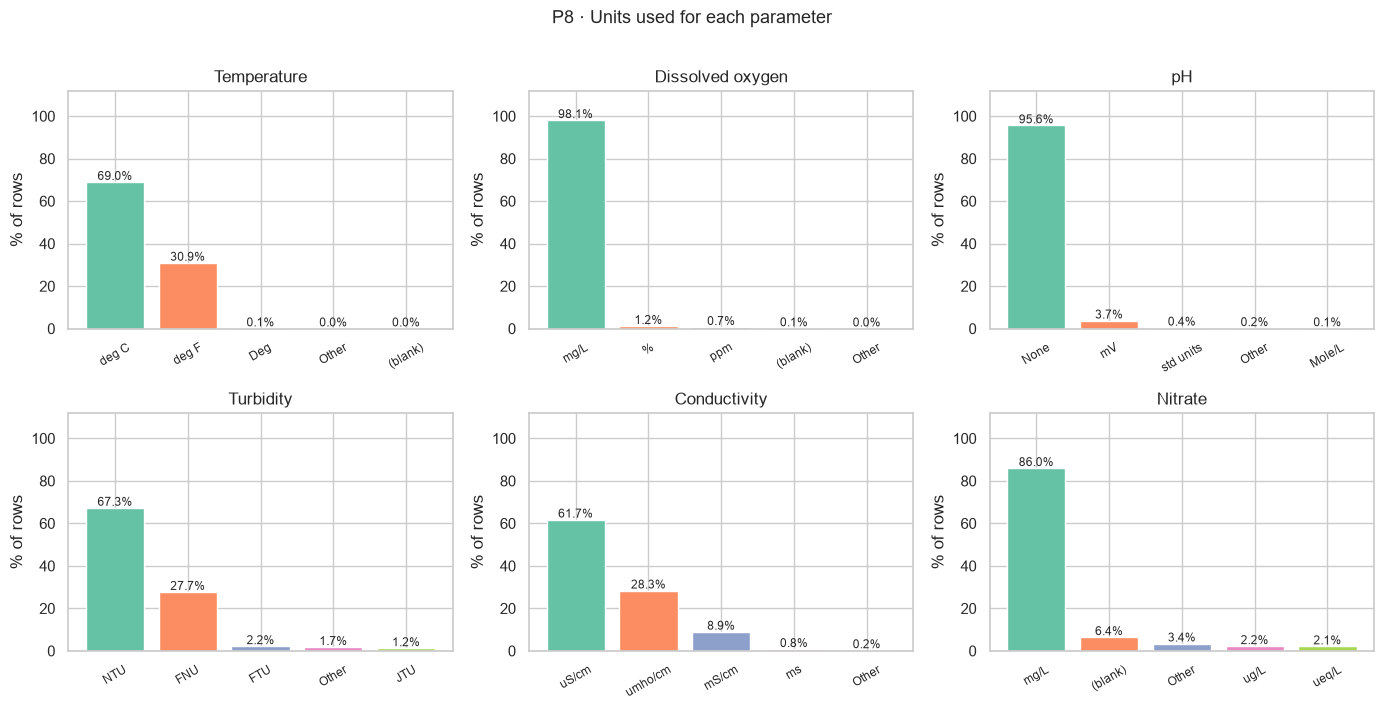

In [11]:
un = q("SELECT param, coalesce(unit, '(blank)') AS unit, count(*) n FROM v GROUP BY ALL")
un['pct'] = un.n / un.groupby('param').n.transform('sum') * 100
un = un.sort_values(['param', 'n'], ascending=[True, False])
save_tab(un, '08_units_by_parameter')
un['unit_g'] = np.where(un.groupby('param').cumcount() < 4, un.unit, 'Other')
ug = un.groupby(['param', 'unit_g']).pct.sum().reset_index()
print('Units per parameter (top 4 + Other):')
display(ug.pivot(index='param', columns='unit_g', values='pct').loc[PARAMS].round(2).fillna(0))
print('Distinct units per parameter:'); display(un.groupby('param').unit.nunique().loc[PARAMS].rename('distinct units'))
EQUIV = {'Temperature, water': ['deg C'], 'Dissolved oxygen (DO)': ['mg/L', 'ppm'], 'pH': ['None', 'std units', '(blank)'],
         'Turbidity': ['NTU', 'FNU', 'FTU', 'NTRU', 'JTU'], 'Conductivity': ['uS/cm', 'umho/cm'], 'Nitrate': ['mg/L', 'mg/l as N', 'ppm']}
CONVERT = {'Temperature, water': ['deg F'], 'Conductivity': ['mS/cm', 'mho/cm', 'uS/m'], 'Nitrate': ['ug/L', 'ueq/L', 'umol/L', 'mg/l asNO3']}
def unit_status(p, u):
    if u in EQUIV.get(p, []): return 'Standard / equivalent'
    if p == 'Dissolved oxygen (DO)' and u == '%': return 'Different measure (% saturation)'
    if u in CONVERT.get(p, []): return 'Convertible (formula)'
    return 'Unusable / invalid'
un['status'] = [unit_status(p_, u_) for p_, u_ in zip(un.param, un.unit)]
ust = un.pivot_table(index='param', columns='status', values='n', aggfunc='sum', fill_value=0).loc[PARAMS]
ust.index = ust.index.map(SHORT)
print('Unit status (rows):'); display(save_tab(ust, '08_unit_status', index=True))
unit_convert_rows = int(ust.get('Convertible (formula)', pd.Series(0)).sum())
unit_bad_rows = int(ust.get('Unusable / invalid', pd.Series(0)).sum())
unit_pct_rows = int(ust.get('Different measure (% saturation)', pd.Series(0)).sum())

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, p in zip(axes.flat, PARAMS):
    d = ug[ug.param == p].sort_values('pct', ascending=False)
    ax.bar(d.unit_g, d.pct, color=sns.color_palette('Set2', len(d)))
    for i, v_ in enumerate(d.pct): ax.text(i, v_ + 1, f'{v_:.1f}%', ha='center', fontsize=8.5)
    ax.set(title=SHORT[p], ylim=(0, 112), ylabel='% of rows'); ax.tick_params(axis='x', rotation=30, labelsize=8.5)
fig.suptitle('P8 · Units used for each parameter', y=1.01, fontsize=13)
save_fig('08_units_by_parameter')

**Why this chart:** one small panel per parameter makes the unit mix visible for each; a single bar means a clean parameter, several bars mean conversion is needed.

**🔎 Inference (P8): units**
- **Temperature: 31% (885,447 rows) is in °F**, so averaging without conversion would be badly wrong. These convert exactly with °C = (°F − 32) × 5/9.
- **Conductivity: 3 equivalent spellings** (µS/cm, µmho/cm, which are identical) plus **mS/cm (14,037)**, which needs ×1000.
- **Nitrate: 7+ units** (mg/L, µg/L, µeq/L, µmol/L…). 2,825 rows are convertible by formula; 4,287 are unusable (blank or impossible units).
- **pH: 708,012 rows have the unit written as the text "None"**, which is correct because pH has no unit. But **27,623 pH rows are in mV** (millivolts, the raw electrode signal). These **cannot** be turned into pH without calibration data, so they are unusable.
- **DO: 9,074 rows are % saturation**, a different measure from mg/L, so they are kept separate.
- **Totals:**
  - **902,542 rows (18.2%) need a unit conversion**
  - **42,481 rows (0.9%) have an unusable unit**
- **Impact:** unit standardisation is the **single largest cleaning step** by row count. Without it, temperature and conductivity analysis, exceedance flags and every model would be wrong.

## 9 · Zero, negative and physically impossible values
**What we check:** in each parameter's main unit, how many values are zero, negative or outside what is **physically possible**:

| Parameter (main unit) | Possible range used | Reason |
|---|---|---|
| Temperature (°C) | −5 to 50 | liquid water in nature |
| Dissolved oxygen (mg/L) | 0 to 25 | highest natural super-saturation is about 20 mg/L |
| pH | 0 to 14 | the pH scale |
| Turbidity (NTU/FNU) | ≥ 0 | cannot be negative |
| Conductivity (µS/cm) | ≥ 0 | cannot be negative |
| Nitrate (mg/L) | ≥ 0 | concentration cannot be negative |

**Why it matters:** the brief says zero, negative and extreme values must be **inspected before deciding** whether they are errors. Zero can be real (e.g. nitrate below detection, 0 °C ice water); negative turbidity cannot.

,Parameter,Main unit,Possible range,Numeric rows,Zero,Negative,Impossible,% impossible,Raw min,Raw max
0,Temperature,°C,-5 to 50,1971361,3008,4245,11115,0.564,-14.707222,25430.00
1,Dissolved oxygen,mg/L (ppm),0 to 25,762330,6192,555,1712,0.225,-2.000000,6936396.00
2,pH,pH units,0 to 14,703799,81,81,233,0.033,-24.430000,8325.00
3,Turbidity,NTU/FNU,0 to ∞,345949,2923,1631,1631,0.471,-6419.250000,97225.28
4,Conductivity,µS/cm (µmho/cm),0 to ∞,140631,39,56,56,0.040,-0.300000,220591.00
5,Nitrate,mg/L,0 to ∞,42557,1003,33,33,0.078,-347.590000,225.00


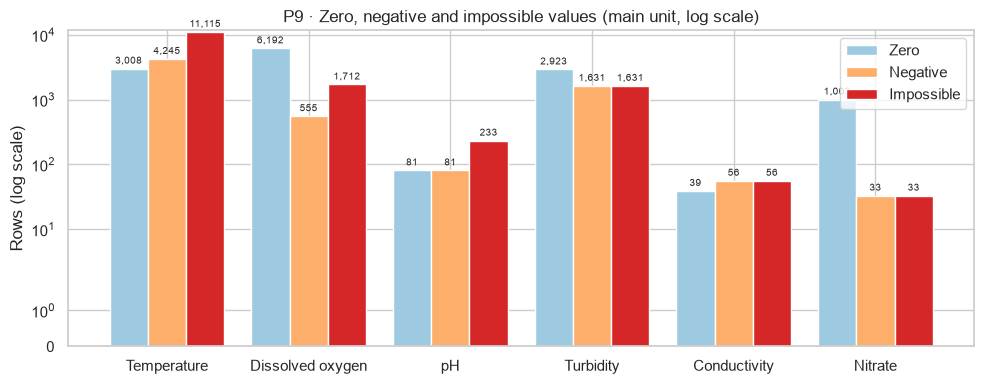

In [12]:
RULES = {'Temperature, water': ("unit = 'deg C'", -5, 50), 'Dissolved oxygen (DO)': ("unit IN ('mg/L','ppm')", 0, 25),
         'pH': ("(unit IS NULL OR unit IN ('None', 'std units'))", 0, 14), 'Turbidity': ("unit IN ('NTU','FNU')", 0, None),
         'Conductivity': ("unit IN ('uS/cm','umho/cm')", 0, None), 'Nitrate': ("unit = 'mg/L'", 0, None)}
rows = []
for p, (cond, lo, hi) in RULES.items():
    hi_sql = f'OR val > {hi}' if hi is not None else ''
    r = q(f'''SELECT count(val) AS numeric_rows, count(*) FILTER (WHERE val = 0) AS zero, count(*) FILTER (WHERE val < 0) AS negative,
                     count(*) FILTER (WHERE val < {lo} {hi_sql}) AS impossible, min(val) AS min, max(val) AS max
              FROM v WHERE param = '{p}' AND {cond}''').iloc[0]
    MAINLBL = {'Temperature, water': '°C', 'Dissolved oxygen (DO)': 'mg/L (ppm)', 'pH': 'pH units', 'Turbidity': 'NTU/FNU',
               'Conductivity': 'µS/cm (µmho/cm)', 'Nitrate': 'mg/L'}
    rows.append({'Parameter': SHORT[p], 'Main unit': MAINLBL[p], 'Possible range': f'{lo} to {hi if hi is not None else "∞"}',
                 'Numeric rows': int(r.numeric_rows), 'Zero': int(r.zero), 'Negative': int(r.negative),
                 'Impossible': int(r.impossible), '% impossible': round(r.impossible / r.numeric_rows * 100, 3),
                 'Raw min': r['min'], 'Raw max': r['max']})
imposs = pd.DataFrame(rows)
display(save_tab(imposs, '09_zero_negative_impossible'))

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(imposs)); w = 0.27
for i, (c, col) in enumerate([('Zero', '#9ecae1'), ('Negative', '#fdae6b'), ('Impossible', '#d62728')]):
    b = ax.bar(x + (i - 1) * w, imposs[c], w, label=c, color=col)
    ax.bar_label(b, labels=[f'{v_:,}' for v_ in imposs[c]], fontsize=7.5, padding=2)
ax.set_xticks(x, imposs.Parameter); ax.set_yscale('symlog'); ax.legend()
ax.set(title='P9 · Zero, negative and impossible values (main unit, log scale)', ylabel='Rows (log scale)')
save_fig('09_zero_negative_impossible')

**Why this chart:** grouped bars compare the three checks for each parameter; a log scale is needed because the counts range from single digits to tens of thousands.

**🔎 Inference (P9): zero, negative and impossible values**
- **14,780 values (0.3%) are physically impossible** in their stated unit. Examples:
  - Temperature up to **25,430 °C**
  - DO up to **6,936,396 mg/L**
  - pH from **−24 to 8,325**
  - Turbidity down to **−6,419 NTU**
- **Temperature has the most impossible values (11,115)**. About **10,848 of them lie between 50 and 120 "°C"**, exactly the range of normal water temperatures in **°F**. These are most likely **°F values labelled as °C**, a unit-entry error, not real heat.
- **Zero values are mostly plausible:** 0 °C (ice-cold water), 0 nitrate (below detection), 0 turbidity (very clear water). Zero is **not** treated as an error.
- **Impact:** impossible values are **flagged and excluded from analysis, not deleted**, so the warehouse still counts them in data-quality reports. Without this step the raw maximums would destroy every average and chart (see P10).

## 10 · Raw distributions and summary statistics (main unit, before cleaning)
**What we check:** mean, median, spread (standard deviation), minimum, quartiles, maximum, **skewness** (lopsidedness) and **kurtosis** (how heavy the extreme tails are), plus a histogram of each parameter.
**Why it matters:** this shows each parameter's normal range, whether the raw data hides absurd values (a huge max or a mean far from the median), and which parameters are **skewed**. Skewed parameters need medians rather than means, and log scales in charts and models.

*Simple terms:* **median** is the middle value. **Skewness ≈ 0** means a symmetric bell; **> 1** means a long tail to the right (a few very large values). **High kurtosis** means extreme values occur more often than in a normal bell curve.

,n,mean,median,std,min,q1,q3,max,skewness,kurtosis,IQR
Parameter,,,,,,,,,,,
Temperature,1971361.0,15.636,15.42,36.924,-14.707,10.858,19.90,25430.00,589.271,366931.701,9.042
Dissolved oxygen,762330.0,17.031,8.11,7944.431,-2.000,6.160,9.86,6936396.00,873.110,762323.599,3.700
pH,703799.0,7.740,7.80,14.564,-24.430,7.260,8.20,8325.00,507.967,282598.136,0.940
Turbidity,345949.0,34.128,4.20,406.753,-6419.250,1.480,10.30,97225.28,72.775,13276.007,8.820
Conductivity,140631.0,1814.407,109.00,7834.498,-0.300,58.300,373.70,220591.00,5.380,32.477,315.400
Nitrate,42557.0,1.839,0.45,5.274,-347.590,0.100,1.60,225.00,4.122,732.723,1.500


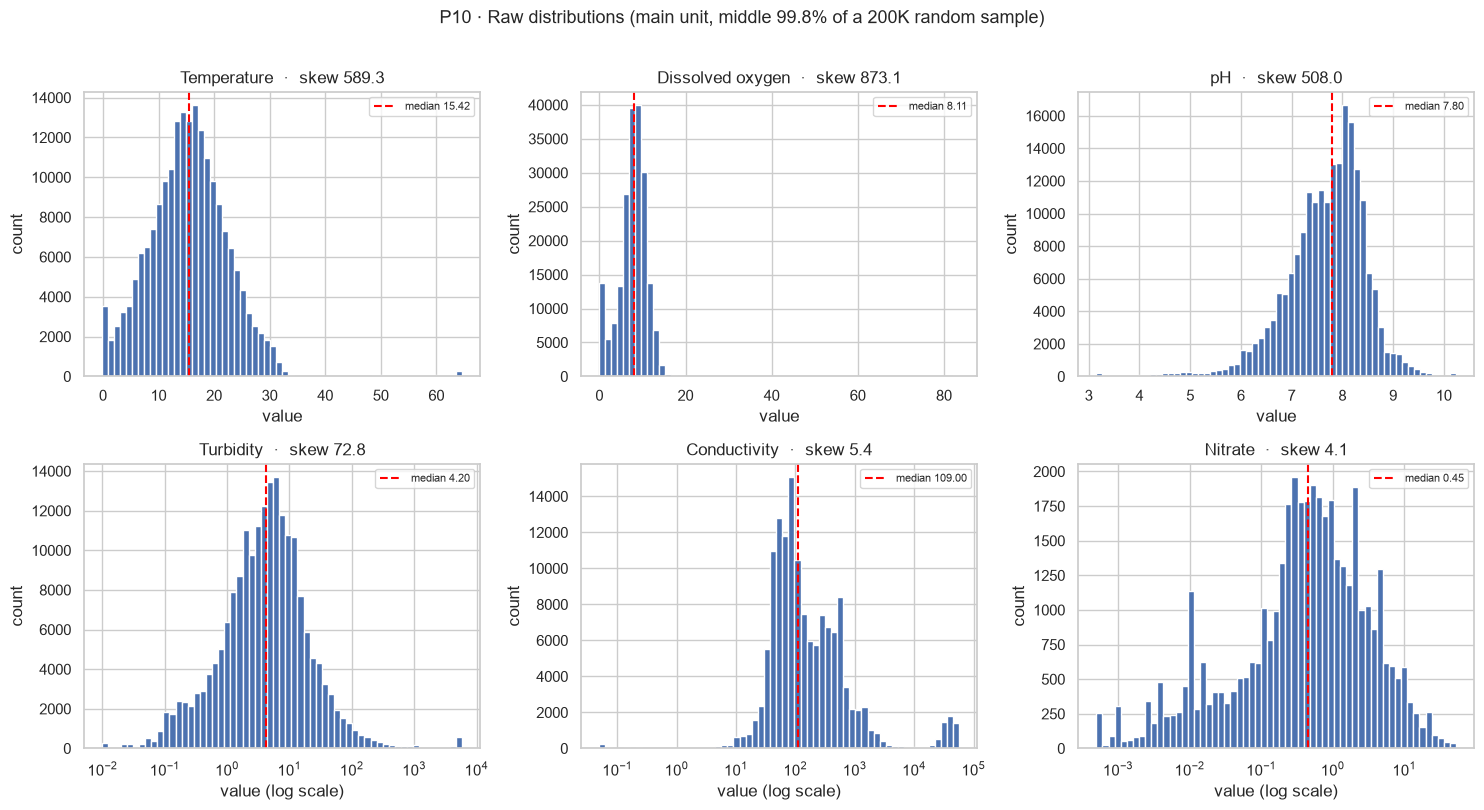

In [13]:
rows, samples = [], {}
for p, (cond, lo, hi) in RULES.items():
    r = q(f'''SELECT count(val) n, avg(val) mean, median(val) median, stddev(val) std, min(val) min,
                     quantile_cont(val, 0.25) q1, quantile_cont(val, 0.75) q3, max(val) max,
                     skewness(val) skewness, kurtosis(val) kurtosis
              FROM v WHERE param = '{p}' AND {cond} AND val IS NOT NULL''').iloc[0]
    rows.append({'Parameter': SHORT[p], **{k: r[k] for k in r.index}})
    samples[p] = q(f"SELECT val FROM (SELECT val FROM v WHERE param = '{p}' AND {cond} AND val IS NOT NULL) "
                   f"USING SAMPLE reservoir(200000 ROWS) REPEATABLE (42)").val
stats = pd.DataFrame(rows).set_index('Parameter')
stats['IQR'] = stats.q3 - stats.q1
display(save_tab(stats.round(3), '10_raw_numeric_summary', index=True))

LOG = {'Turbidity', 'Conductivity', 'Nitrate'}
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, p in zip(axes.flat, RULES):
    s = samples[p]
    if SHORT[p] in LOG:
        s = s[s > 0]; bins = np.logspace(np.log10(s.quantile(0.001)), np.log10(s.quantile(0.999)), 60)
        ax.hist(s.clip(upper=s.quantile(0.999)), bins=bins, color='#4C72B0'); ax.set_xscale('log'); xl = ' (log scale)'
    else:
        lo_, hi_ = s.quantile([0.001, 0.999])
        ax.hist(s.clip(lo_, hi_), bins=60, color='#4C72B0'); xl = ''
    ax.axvline(stats.loc[SHORT[p], 'median'], color='red', ls='--', label=f"median {stats.loc[SHORT[p], 'median']:.2f}")
    ax.set(title=f"{SHORT[p]}  ·  skew {stats.loc[SHORT[p], 'skewness']:.1f}", xlabel=f"value{xl}", ylabel='count'); ax.legend(fontsize=8)
fig.suptitle('P10 · Raw distributions (main unit, middle 99.8% of a 200K random sample)', y=1.01, fontsize=13)
save_fig('10_raw_distributions')

**Why this chart:** histograms show the shape (bell, skewed, two peaks). The skewed parameters use a log axis so their shape is visible, and the extreme 0.1% at each end is clipped **only for drawing**; the table above uses all values.

**🔎 Inference (P10): raw distributions and statistics (before cleaning)**
- **The raw means are distorted by bad values:**
  - The DO mean is **17.0 mg/L** but the median is **8.1 mg/L**, with skewness **873**, because of a few impossible values (up to 6.9 million).
  - Temperature's skewness is **589** and pH's is **508** for the same reason.
  - After cleaning, these should become near-symmetric (skewness close to 0).
- **The typical (median) values are realistic:** temperature **15.4 °C**, DO **8.1 mg/L**, pH **7.8**, turbidity **4.2 NTU**, conductivity **109 µS/cm**, nitrate **0.45 mg/L**.
- **Turbidity, conductivity and nitrate are genuinely right-skewed** (most values small, a few very large), so they are shown on a log scale. The conductivity histogram has a **second peak around 10,000–50,000 µS/cm**: these are **estuary and ocean-water sites** (salt water), a real group, not an error.
- **The temperature histogram shows a small bump around 60–65 "°C"**, the °F mislabelling found in P9. The **DO histogram has a spike near 0–1 mg/L (47,101 rows)**: low-oxygen (hypoxic) water, often from deep lake layers in depth profiles, which is a real and important water-quality signal.
- **Impact:**
  - Use **medians and IQR** (not means) for skewed parameters.
  - Use **log scales** in charts.
  - Consider **log transforms** for turbidity, conductivity and nitrate in regression.

## 11 · Outliers (IQR rule)
**What we check:** values far outside the typical range using the **IQR rule**. IQR is the spread of the middle 50% of values (Q3 − Q1).
- **Mild outlier:** beyond Q1 − 1.5×IQR or Q3 + 1.5×IQR
- **Extreme outlier:** beyond Q1 − 3×IQR or Q3 + 3×IQR

**Why it matters:** an outlier can be an **error** (a typo, the wrong unit) or a **real event** (a storm raising turbidity, low oxygen in summer). For water safety, real extremes are exactly what we want to detect, so outliers are **flagged, not deleted**, unless they are physically impossible (section 9).

,Parameter,Q1,Q3,IQR,Upper fence (3×IQR),Mild outliers (1.5×IQR),Extreme outliers (3×IQR),% extreme
0,Temperature,10.858,19.90,9.042,47.026,13525,11875,0.60
1,Dissolved oxygen,6.160,9.86,3.700,20.961,42457,1294,0.17
2,pH,7.260,8.20,0.940,11.020,17298,3097,0.44
3,Turbidity,1.480,10.30,8.820,36.760,38153,24020,6.94
4,Conductivity,58.300,373.70,315.400,1319.900,14568,10668,7.59
5,Nitrate,0.100,1.60,1.500,6.100,5198,2993,7.03


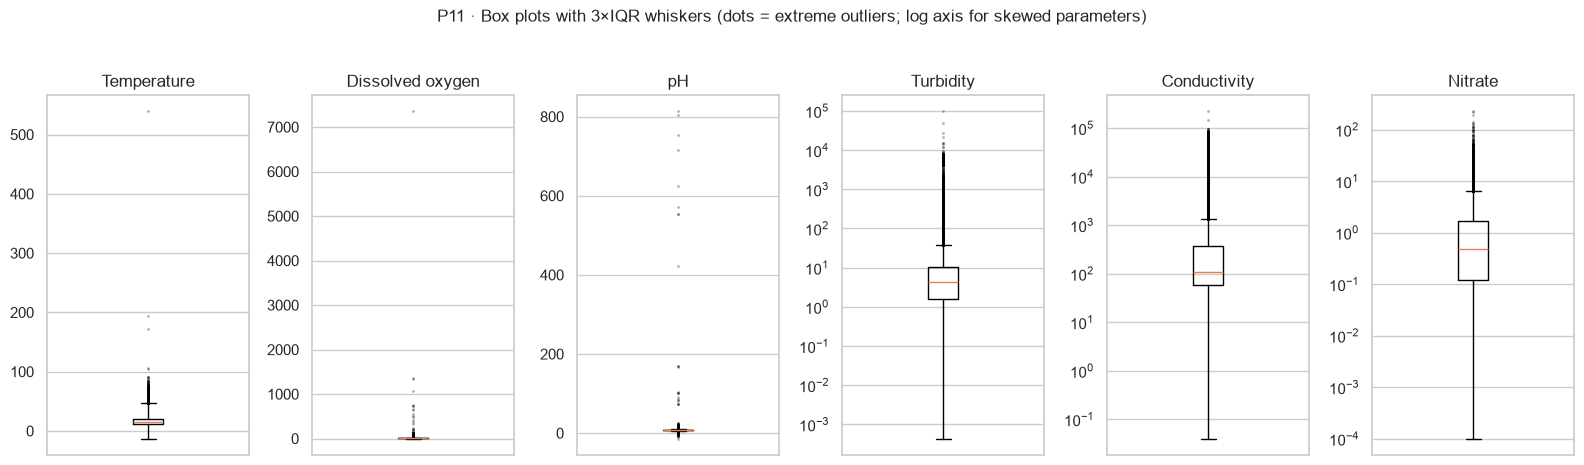

In [14]:
rows = []
for p, (cond, lo, hi) in RULES.items():
    st = stats.loc[SHORT[p]]; iqr = st.q3 - st.q1
    r = q(f'''SELECT count(*) FILTER (WHERE val < {st.q1 - 1.5*iqr} OR val > {st.q3 + 1.5*iqr}) mild,
                     count(*) FILTER (WHERE val < {st.q1 - 3*iqr} OR val > {st.q3 + 3*iqr}) extreme
              FROM v WHERE param = '{p}' AND {cond} AND val IS NOT NULL''').iloc[0]
    rows.append({'Parameter': SHORT[p], 'Q1': st.q1, 'Q3': st.q3, 'IQR': iqr, 'Upper fence (3×IQR)': st.q3 + 3*iqr,
                 'Mild outliers (1.5×IQR)': int(r.mild), 'Extreme outliers (3×IQR)': int(r.extreme),
                 '% extreme': round(r.extreme / st.n * 100, 2)})
out = pd.DataFrame(rows)
display(save_tab(out.round(3), '11_outliers_iqr'))

fig, axes = plt.subplots(1, 6, figsize=(16, 4.5))
for ax, p in zip(axes, RULES):
    s = samples[p]
    if SHORT[p] in LOG: s = s[s > 0]; ax.set_yscale('log')
    ax.boxplot(s, whis=3, showfliers=True, flierprops=dict(marker='.', markersize=2, alpha=0.3))
    ax.set(title=SHORT[p], xticks=[])
fig.suptitle('P11 · Box plots with 3×IQR whiskers (dots = extreme outliers; log axis for skewed parameters)', y=1.03, fontsize=12)
save_fig('11_outliers_boxplots')

**Why this chart:** a box plot shows the median (line), the middle 50% (box), the normal range (whiskers at 3×IQR) and every extreme value (dots) at the same time.

**🔎 Inference (P11): outliers (IQR rule)**
- **Extreme outliers (beyond 3×IQR):**
  - Temperature 0.6%, DO 0.17%, pH 0.44%
  - **Turbidity 6.9%, conductivity 7.6%, nitrate 7.0%**
- The high outlier shares for turbidity, conductivity and nitrate are **expected for skewed data**. The IQR rule assumes a roughly symmetric shape, so on a long-tailed distribution it labels many *real* high values as outliers: storm turbidity, salty estuary conductivity, nitrate near farms.
- **Impact:**
  - Outliers are **kept and flagged (`IsExtremeOutlier`)**, not removed, because high turbidity or nitrate is exactly what an exceedance dashboard must show.
  - Only **physically impossible** values (P9) are excluded.
  - For skewed parameters, Step 2 also computes outliers on the **log scale**, which is fairer.

## 12 · Dates and times
**What we check:**
- every date can be read and falls inside the study period
- results per month (gaps or spikes)
- how often the **time of day** is missing, and whether **00:00:00** appears as a fake midnight placeholder
- time zones used
- whether any **end time is earlier than the start time** (broken event order)

**Why it matters:** the warehouse's Date and Time dimensions, the seasonal analysis and the real-time replay (which plays events in time order) all depend on correct timestamps.

,Rows,% of rows
unreadable_date,0,0.000
outside_period,0,0.000
time_missing,1423442,28.709
midnight_000000,539046,10.872
time_without_zone,0,0.000
has_end_date,2669509,53.840
end_before_start,94,0.002


,kind,midnight,with_time,% of timed rows at 00:00:00
0,Automatic logger / time series,529625,764353,69.29
1,Discrete field visit / sample,9421,2770443,0.34


,time_zone,n,pct
0,(blank),1423442,28.71
1,CDT,1123691,22.66
2,PDT,725467,14.63
3,EST,674295,13.60
4,EDT,349240,7.04
5,CST,238093,4.80
6,MST,174966,3.53
7,PST,147281,2.97
8,MDT,46140,0.93
9,HAST,27020,0.54


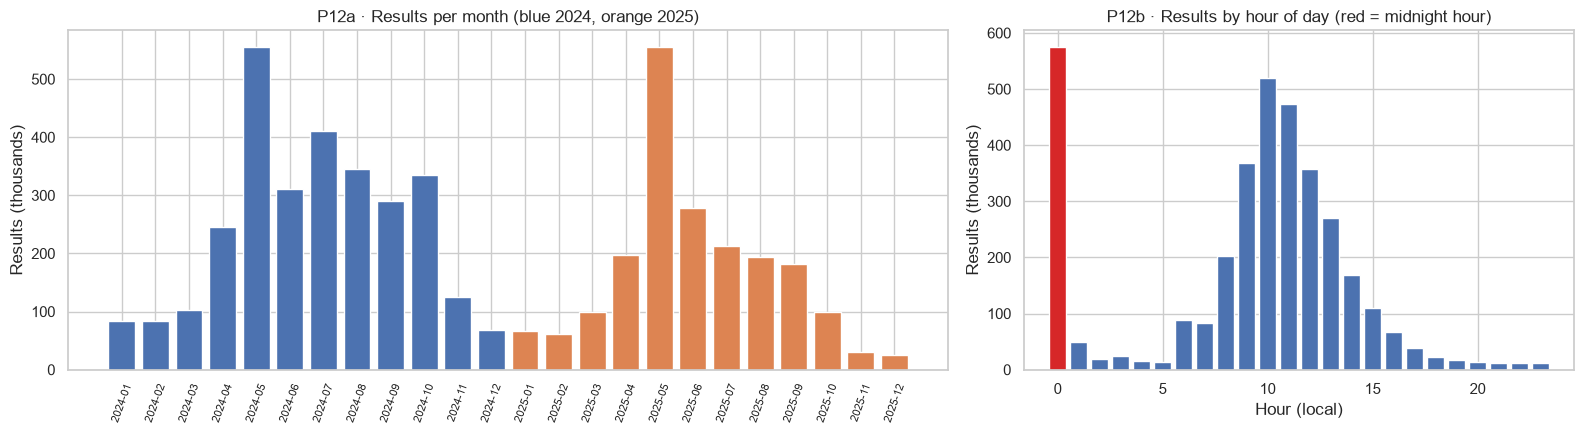

In [15]:
ts = q('''SELECT count(*) FILTER (WHERE dt IS NULL) AS unreadable_date,
                 count(*) FILTER (WHERE dt < DATE '2024-01-01' OR dt > DATE '2025-12-31') AS outside_period,
                 count(*) FILTER (WHERE tm IS NULL) AS time_missing,
                 count(*) FILTER (WHERE tm = '00:00:00') AS midnight_000000,
                 count(*) FILTER (WHERE tm IS NOT NULL AND tz IS NULL) AS time_without_zone,
                 count(*) FILTER (WHERE end_date_raw IS NOT NULL) AS has_end_date,
                 count(*) FILTER (WHERE TRY_CAST(end_date_raw || ' ' || coalesce(end_tm, '00:00:00') AS TIMESTAMP)
                                      < TRY_CAST(date_raw || ' ' || coalesce(tm, '00:00:00') AS TIMESTAMP)) AS end_before_start
          FROM v''').T.rename(columns={0: 'Rows'})
ts['% of rows'] = (ts.Rows / N * 100).round(3)
display(save_tab(ts, '12_timestamp_checks', index=True))
mid = q('''SELECT CASE WHEN act_type ILIKE '%Logger%' OR act_type ILIKE '%Continuous%' OR act_type ILIKE '%Time Series%'
                       THEN 'Automatic logger / time series' ELSE 'Discrete field visit / sample' END AS kind,
                  count(*) FILTER (WHERE tm = '00:00:00') AS midnight, count(*) FILTER (WHERE tm IS NOT NULL) AS with_time
           FROM v GROUP BY 1''')
mid['% of timed rows at 00:00:00'] = (mid.midnight / mid.with_time * 100).round(2)
display(save_tab(mid, '12_midnight_by_activity'))
tzc = q("SELECT coalesce(tz, '(blank)') AS time_zone, count(*) n FROM v GROUP BY 1 ORDER BY n DESC")
tzc['pct'] = (tzc.n / N * 100).round(2); display(save_tab(tzc, '12_time_zones'))

mon = q("SELECT strftime(dt, '%Y-%m') AS month, count(*) n FROM v WHERE dt IS NOT NULL GROUP BY 1 ORDER BY 1")
save_tab(mon, '12_monthly_volume')
hr = q("SELECT TRY_CAST(substr(tm, 1, 2) AS INT) AS hour, count(*) n FROM v WHERE tm IS NOT NULL GROUP BY 1 ORDER BY 1")
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={'width_ratios': [1.6, 1]})
axes[0].bar(mon.month, mon.n / 1e3, color=['#4C72B0' if m.startswith('2024') else '#DD8452' for m in mon.month])
axes[0].set(title='P12a · Results per month (blue 2024, orange 2025)', ylabel='Results (thousands)'); axes[0].tick_params(axis='x', rotation=70, labelsize=8)
axes[1].bar(hr.hour, hr.n / 1e3, color=['#d62728' if h == 0 else '#4C72B0' for h in hr.hour])
axes[1].set(title='P12b · Results by hour of day (red = midnight hour)', xlabel='Hour (local)', ylabel='Results (thousands)')
save_fig('12_monthly_and_hourly')

**Why these charts:** the monthly bars show coverage across both years and the seasonal sampling rhythm; the hourly bars expose a fake midnight spike if one exists (red bar).

**🔎 Inference (P12): dates and times**
- **Dates are clean:** 0 unreadable and 0 outside 2024–2025, so every result fits the Date dimension.
- **Strong seasonal sampling rhythm:**
  - Volume peaks in **May (about 556K results in both 2024 and 2025)** and stays high through October.
  - It falls to about 25–85K in winter months, because many sites are only sampled in the ice-free season.
  - **2025 has fewer results than 2024 from July onward** (Nov–Dec 2025 only 31K and 25K), probably because recent data is still being uploaded to WQP.
- **Time of day is missing for 28.7%**, and **all 1.42M rows without a time also have no time zone**, so they cannot be converted to UTC.
- **Midnight spike:** 539,046 rows are at exactly 00:00:00. **98% of them (529,625) come from loggers / daily summaries**, where midnight means "this day" rather than a real reading time. In discrete field visits only **0.34%** are at midnight, mostly placeholders.
- **94 rows** have an end time earlier than the start time.
- **Impact:**
  - The **TimeBand** attribute needs care: logger midnight rows count as *whole-day*, and discrete midnight rows as *unknown*.
  - The month pattern means seasonal comparisons must use **rates/medians, not raw counts**.
  - For the **real-time replay**, events are ordered by date and then time, with unknown times placed at a fixed point of the day.

## 13 · Category and code validation
**What we check:** the values used in the coded fields: activity type, result status, value type, water type (media subdivision) and qualifier flags.
**Why it matters:**
- **Quality-control** records (blanks, replicates, calibration checks) test the *equipment*, not the *water*, so they must be separated from real results.
- **Rejected** results were refused by the data provider.
- **Unknown** or blank codes must become an explicit *Unknown / Not Reported* member in the warehouse instead of being silently dropped (as the brief requires).

,activity_group,n,pct
0,Field measurement,4599025,92.755
1,Lab sample,328414,6.624
2,Quality control (blank/replicate/calibration),29108,0.587
3,Unknown,1691,0.034


,result_status,n,pct
0,Final,4540954,91.584
1,Accepted,302583,6.103
2,Unreviewed,42944,0.866
3,Raw,35983,0.726
4,Validated,21882,0.441
5,Preliminary,7355,0.148
6,Provisional,6362,0.128
7,Rejected,175,0.004


,value_type,n,pct
0,Actual,4124140,83.178
1,Calculated,831047,16.761
2,Estimated,2539,0.051
3,(blank),384,0.008
4,Blank Corrected Calc,128,0.003


,water_type,n,pct
0,(blank),3869255,78.037
1,Surface Water,1049851,21.174
2,Groundwater,25020,0.505
3,Ocean Water,11189,0.226
4,Wastewater Treatment Plant Effluent,2395,0.048
5,Stormwater,384,0.008
6,Drinking Water,57,0.001
7,Deionized Water,48,0.001
8,Leachate,19,0.000
9,Industrial Effluent,9,0.000


,qualifier,n,pct
0,(blank),4849506,97.807
1,SUS,91592,1.847
2,QCI,8058,0.163
3,LT;MDL,1780,0.036
4,J,956,0.019
5,U,881,0.018
6,OTHER,780,0.016
7,FQC,779,0.016
8,H,599,0.012
9,D,497,0.010


Quality-control activity types: 19   ·   Rows flagged suspect (qualifier contains SUS): 91,600


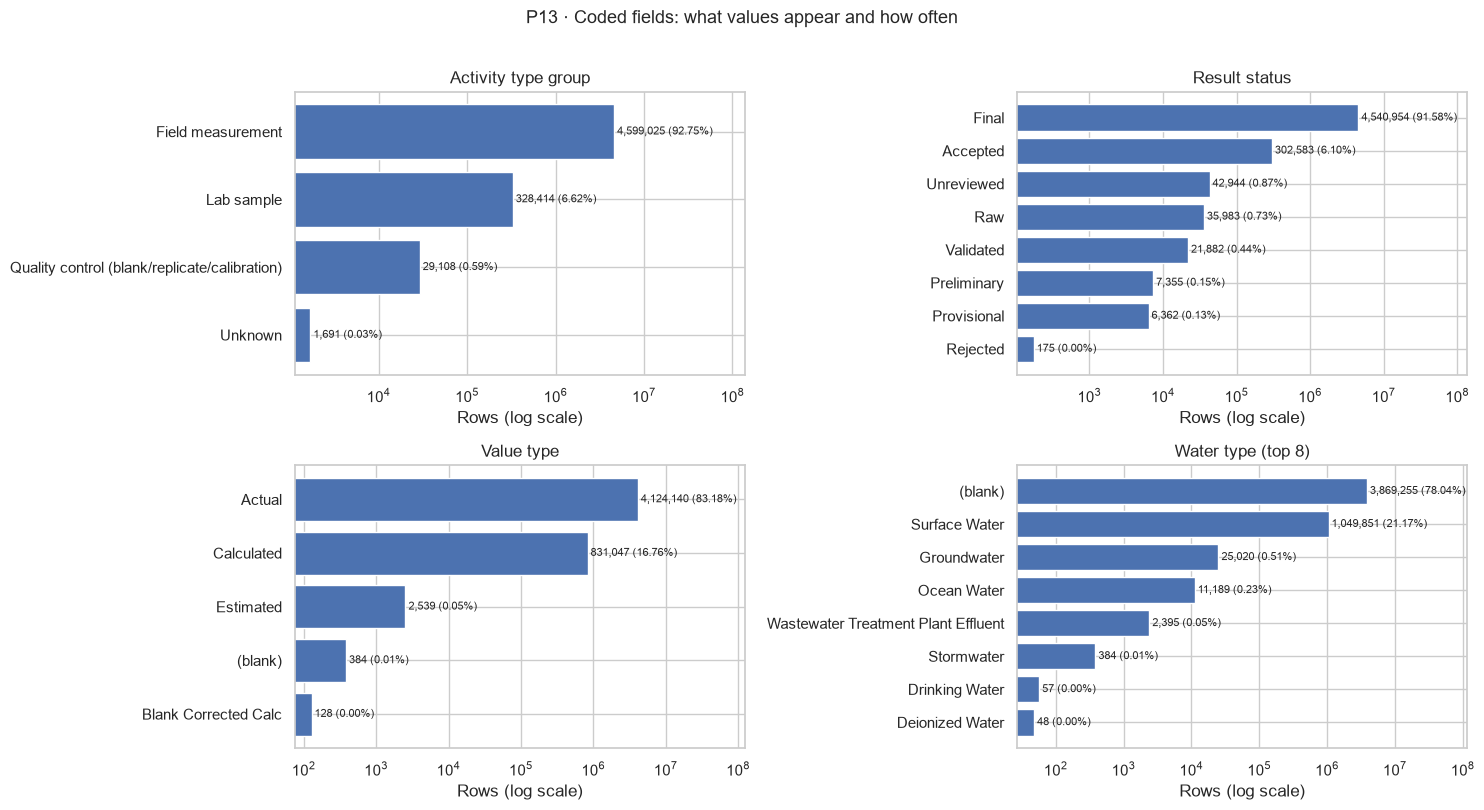

In [16]:
act = q('''SELECT CASE WHEN act_type ILIKE 'Quality Control%' THEN 'Quality control (blank/replicate/calibration)'
                       WHEN act_type ILIKE 'Field Msr%' THEN 'Field measurement'
                       WHEN act_type ILIKE 'Sample%' THEN 'Lab sample'
                       WHEN act_type = 'Unknown' THEN 'Unknown'
                       ELSE coalesce(act_type, '(blank)') END AS activity_group, count(*) n
           FROM v GROUP BY 1 ORDER BY n DESC''')
stt = q("SELECT coalesce(status, '(blank)') AS result_status, count(*) n FROM v GROUP BY 1 ORDER BY n DESC")
vty = q("SELECT coalesce(value_type, '(blank)') AS value_type, count(*) n FROM v GROUP BY 1 ORDER BY n DESC")
med = q("SELECT coalesce(media_sub, '(blank)') AS water_type, count(*) n FROM v GROUP BY 1 ORDER BY n DESC")
qual = q('''SELECT coalesce(qualifier, '(blank)') AS qualifier, count(*) n FROM v GROUP BY 1 ORDER BY n DESC LIMIT 10''')
susp = q("SELECT count(*) n FROM v WHERE qualifier ILIKE '%SUS%'").n[0]
qc_types = q("SELECT count(DISTINCT act_type) n FROM v WHERE act_type ILIKE 'Quality Control%'").n[0]
for name, d in [('13_activity_groups', act), ('13_result_status', stt), ('13_value_type', vty), ('13_water_type', med), ('13_qualifier_top10', qual)]:
    d['pct'] = (d.n / N * 100).round(3); display(save_tab(d, name))
print(f'Quality-control activity types: {qc_types}   ·   Rows flagged suspect (qualifier contains SUS): {susp:,}')

fig, axes = plt.subplots(2, 2, figsize=(15, 8))
for ax, (d, col, t) in zip(axes.flat, [(act, 'activity_group', 'Activity type group'), (stt, 'result_status', 'Result status'),
                                        (vty, 'value_type', 'Value type'), (med.head(8), 'water_type', 'Water type (top 8)')]):
    ax.barh(d[col], d.n, color='#4C72B0'); ax.set_xscale('log'); ax.invert_yaxis()
    for i, (n_, p_) in enumerate(zip(d.n, d.pct)): ax.text(n_, i, f' {n_:,} ({p_:.2f}%)', va='center', fontsize=8)
    ax.set(title=t, xlabel='Rows (log scale)'); ax.set_xlim(right=d.n.max() * 30)
fig.suptitle('P13 · Coded fields: what values appear and how often', y=1.01, fontsize=13)
save_fig('13_coded_fields')

**Why this chart:** four panels show all coded fields together. A log axis is used because one category usually dominates and would hide small but important groups such as *Rejected* or *Quality control*.

**🔎 Inference (P13): coded fields**
- **Activity type:** **92.8% are field measurements** (sensor/probe readings), 6.6% lab samples, and **29,108 rows (0.6%) are quality-control records** across **19 QC activity types** (field blanks, replicates, calibration checks), plus 1,691 *Unknown*.
- **Result status:** **91.6% Final** and 6.1% Accepted. Only **175 rows are Rejected**. About 92K are Unreviewed / Raw / Preliminary / Provisional (not yet final).
- **Value type:** 83% *Actual* and **16.8% *Calculated***, which matches the summary-statistic rows from P6b.
- **Water type:** 78% blank. Of the known values, **Surface Water** dominates (21.2%), then Groundwater (0.5%) and Ocean Water (0.2%).
- **Qualifier:** **91,600 rows (1.85%) are flagged *SUS* (suspect)** by the provider.
- **Impact:**
  - **QC rows test the equipment, not the water**, so they are excluded from water-quality analysis but kept for audit.
  - **Rejected and suspect** values are excluded from analysis.
  - **Not-yet-final** results are kept with an `IsProvisional` flag so the dashboard can filter them.
  - *Unknown* activity types become an explicit **Unknown** dimension member rather than being dropped.

## 14 · Geography: are the site coordinates valid?
**What we check:**
- missing, unreadable, zero or out-of-range latitude/longitude
- **positive longitude north of 20°N**: all US states and Puerto Rico have *negative* longitudes, so a positive one there is probably a missing minus sign. Guam and the Northern Mariana Islands legitimately have positive longitudes but lie south of 20°N, so they are not counted.
- points near **(0°, 0°)**, a classic placeholder location in the Gulf of Guinea
- sites whose coordinates **change between records** (the same site ID with different locations)

**Why it matters:** the map, the Region dimension and the regional analysis rely on coordinates. This results file has **no state or site-type column**, so region must come from coordinates (or later from the WQP Station file).

,Rows,% of rows
missing,8477,0.171
unreadable,0,0.000
zero,343,0.007
out_of_range,0,0.000
positive_lon_suspect,1058,0.021
near_null_island,261,0.005


Sites with positive longitude north of 20N: 20; if the sign is flipped they fall at longitudes [-123, -106, -75, -42, -35]
Sites with valid coordinates: 49,063 of 50,476
Sites whose coordinates vary by more than 0.01° (~1 km) between records: 71
Rows without coordinates, by source system:


,provider,sites,n
0,NWIS,1409,8477


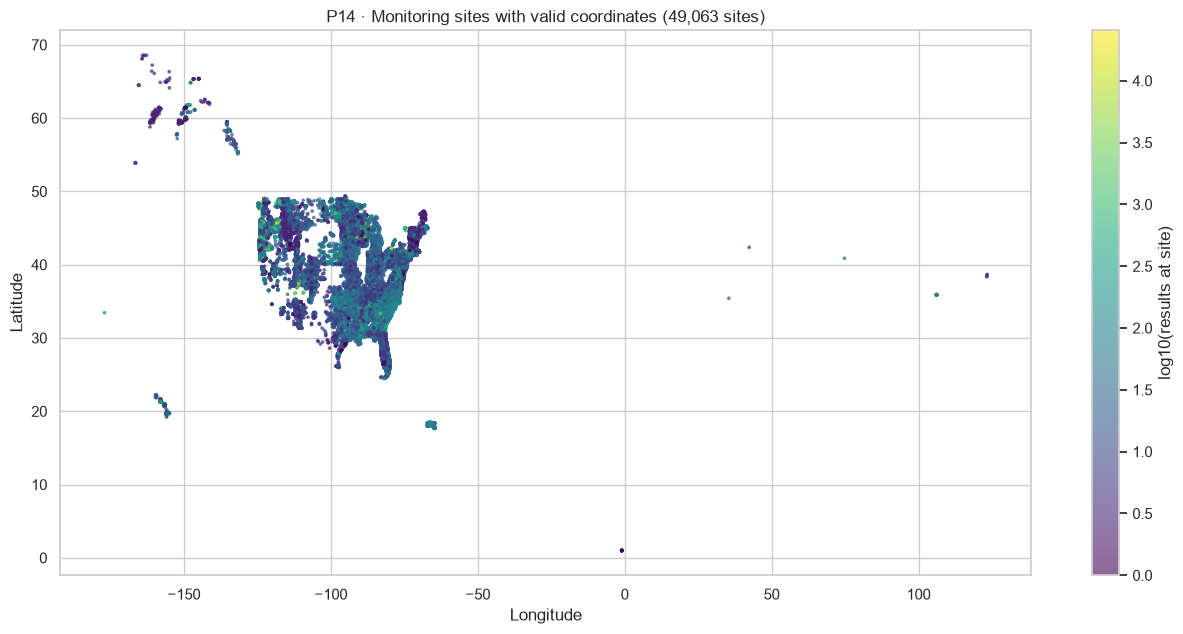

In [17]:
geo = q('''SELECT count(*) FILTER (WHERE lat_raw IS NULL OR lon_raw IS NULL) AS missing,
                  count(*) FILTER (WHERE (lat_raw IS NOT NULL AND lat IS NULL) OR (lon_raw IS NOT NULL AND lon IS NULL)) AS unreadable,
                  count(*) FILTER (WHERE lat = 0 OR lon = 0) AS zero,
                  count(*) FILTER (WHERE lat NOT BETWEEN -90 AND 90 OR lon NOT BETWEEN -180 AND 180) AS out_of_range,
                  count(*) FILTER (WHERE lon > 0 AND lat > 20) AS positive_lon_suspect,
                  count(*) FILTER (WHERE abs(lat) < 2 AND abs(lon) < 2 AND lat <> 0 AND lon <> 0) AS near_null_island
           FROM v''').T.rename(columns={0: 'Rows'})
geo['% of rows'] = (geo.Rows / N * 100).round(3)
display(save_tab(geo, '14_coordinate_checks', index=True))
sites = q('''SELECT site, any_value(provider) provider, count(*) n, avg(lat) lat, avg(lon) lon,
                    max(lat) - min(lat) AS lat_spread, max(lon) - min(lon) AS lon_spread
             FROM v WHERE lat BETWEEN -90 AND 90 AND lon BETWEEN -180 AND 180 AND lat <> 0 AND lon <> 0 GROUP BY site''')
flip = sites[(sites.lon > 0) & (sites.lat > 20)]
print(f'Sites with positive longitude north of 20N: {len(flip)}; if the sign is flipped they fall at longitudes', sorted(set((-flip.lon).round(0).astype(int)))[:12])
moved = int(((sites.lat_spread > 0.01) | (sites.lon_spread > 0.01)).sum())
print(f'Sites with valid coordinates: {len(sites):,} of {int(ov.loc["Monitoring sites", "Value"]):,}')
print(f'Sites whose coordinates vary by more than 0.01° (~1 km) between records: {moved:,}')
nolatsites = q("SELECT provider, count(DISTINCT site) sites, count(*) n FROM v WHERE lat_raw IS NULL GROUP BY 1")
print('Rows without coordinates, by source system:'); display(nolatsites)

fig, ax = plt.subplots(figsize=(13, 6.5))
sc = ax.scatter(sites.lon, sites.lat, c=np.log10(sites.n), s=3, cmap='viridis', alpha=0.6)
plt.colorbar(sc, ax=ax, label='log10(results at site)')
ax.set(title=f'P14 · Monitoring sites with valid coordinates ({len(sites):,} sites)', xlabel='Longitude', ylabel='Latitude')
save_fig('14_site_map')

**Why this chart:** a longitude × latitude scatter is a simple map. If the coordinates are right, the dots trace the shape of the USA; dots in the ocean or a mirrored shape would reveal sign errors. Colour shows how intensively each site is sampled.

**🔎 Inference (P14): geography**
- **49,063 of 50,476 sites (97.2%) have valid coordinates.** The map clearly traces the **USA mainland, Alaska, Hawaii and Puerto Rico**, which confirms that latitude and longitude are mostly correct.
- **All 8,477 rows without coordinates come from NWIS (USGS)**. In this extract the location is given only at station level, so these sites need the WQP Station file to be placed on a map.
- **Problem coordinates:**
  - **343 rows at exactly 0**, plus **261 rows near (0°, 0°)**: placeholders, not real places.
  - **1,058 rows at 20 sites with a positive longitude north of 20°N**. Flipping the sign puts them at −123°, −106° and −75°, which are real US locations (Oregon, New Mexico, the East Coast). This is a **missing minus sign**.
  - **71 sites** have coordinates that change by more than about 1 km between records.
- **Impact:**
  - Suspect coordinates are **set to missing** (Region = *Unknown*) rather than silently corrected, because the true sign cannot be confirmed for certain. Step 2 records the flip candidates for transparency.
  - Since there is **no state column**, the Region dimension is built from coordinates (later enriched from the Station file).

## 15 · Coverage: how evenly are results spread across sites?
**What we check:** the number of results per site, the share of sites with very few results, and how much of the data the busiest 10% of sites hold.
**Why it matters:**
- Sites with very few results give unreliable site averages; the warehouse should show sample counts next to averages.
- Very uneven coverage creates **data skew**, which matters for choosing the distribution key in the distributed warehouse (Step 7).

,Value
Sites,50476.0
Median results per site,20.0
Mean results per site,98.2
Max results at one site,25502.0
Sites with < 5 results,9973.0
% sites with < 5 results,19.8
% of results held by busiest 10% of sites,76.2
"Sites with ≥ 1,000 results",750.0


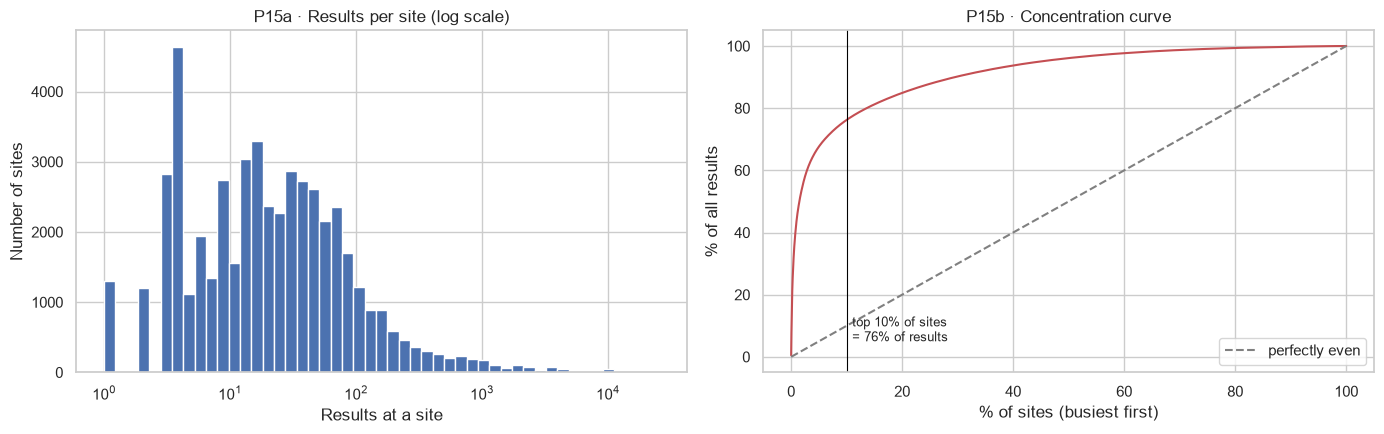

In [18]:
ps = q('SELECT site, count(*) n FROM v GROUP BY site').n.sort_values(ascending=False).reset_index(drop=True)
top10_share = ps.head(int(len(ps) * 0.10)).sum() / ps.sum() * 100
cov = pd.DataFrame({'Value': {
    'Sites': len(ps), 'Median results per site': ps.median(), 'Mean results per site': round(ps.mean(), 1),
    'Max results at one site': ps.max(), 'Sites with < 5 results': int((ps < 5).sum()),
    '% sites with < 5 results': round((ps < 5).mean() * 100, 1), '% of results held by busiest 10% of sites': round(top10_share, 1),
    'Sites with ≥ 1,000 results': int((ps >= 1000).sum())}})
display(save_tab(cov, '15_site_coverage', index=True))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(ps, bins=np.logspace(0, np.log10(ps.max()), 50), color='#4C72B0'); axes[0].set_xscale('log')
axes[0].set(title='P15a · Results per site (log scale)', xlabel='Results at a site', ylabel='Number of sites')
cum = ps.cumsum() / ps.sum() * 100
axes[1].plot(np.arange(1, len(ps) + 1) / len(ps) * 100, cum, color='#C44E52')
axes[1].plot([0, 100], [0, 100], ls='--', color='grey', label='perfectly even')
axes[1].axvline(10, color='black', lw=0.8); axes[1].text(11, 5, f'top 10% of sites\n= {top10_share:.0f}% of results', fontsize=9)
axes[1].set(title='P15b · Concentration curve', xlabel='% of sites (busiest first)', ylabel='% of all results'); axes[1].legend()
save_fig('15_site_coverage')

**Why these charts:** the log histogram shows how many sites have few vs many results; the concentration curve (busiest sites first) measures inequality. The further it bends above the dashed line, the more uneven the coverage.

**🔎 Inference (P15): coverage across sites**
- **Coverage is very uneven:**
  - The **median site has only 20 results**, but the mean is 98 and the busiest site has **25,502**.
  - **19.8% of sites (9,973) have fewer than 5 results.**
  - **The busiest 10% of sites hold 76.2% of all results**, and only **750 sites** have 1,000 or more.
- **Impact:**
  - **Site averages from a handful of samples are unreliable**, so the dashboard will always show the **sample count next to an average**, and site rankings will use a minimum sample size.
  - Such skew matters for the **distributed warehouse**. Distributing by `LocationKey` across many shards spreads it reasonably, but a few heavy sites can make one shard larger than the others. Step 7 measures this.
  - High volume does not mean high risk: busy sites are simply monitored more (the brief warns against confusing volume with rate).

## 16 · Profiling summary: issues handed to Step 2
Every problem measured above, with its count and the **planned** treatment. Step 2 applies these and records the actual affected rows, so each decision can be traced back to this table.

In [19]:
def g(df, key, col='Rows'): return int(df.loc[key, col])
val_counts = vt.drop(columns=['Total', '% not numeric']).sum()
issues = [
 ('Exact duplicate', 'all columns', int(exact), 'Remove if any', 'Same record twice would double-count'),
 ('Repeat inside a field-visit activity', 'activity+parameter+fraction+statistic+depths+value+unit', sa_disc, 'Keep first copy for analysis, flag the rest', 'In a single visit the same result twice is most likely a duplicate entry'),
 ('Repeat inside a logger activity', 'same key, logger activity', sa_log, 'Keep (separate readings)', 'Loggers store many readings per activity without a per-result time'),
 ('Same-value repeat, time missing', 'site+date+parameter+value, different activities', rep_nt, 'Keep (separate readings); aggregate to site-day where needed', 'Logger readings whose time was not reported; deleting would lose real data'),
 ('Same-value repeat, time known', 'site+date+time+parameter+value, different activities', rep_t, 'Investigate; keep, flag', 'Could be co-located instruments or a re-submission'),
 ('Conflicting repeat (field visits)', 'same key, different value', int(conflict.n_rows), 'Retain all, flag; use the mean per visit in site-level analysis', 'Replicate readings in one visit; neither value can be preferred'),
 ('Mixed grain (summary rows)', 'StatisticalBaseCode', summary_rows, 'Separate from single readings (own flag / fact)', 'A daily mean/min/max is a different grain from one reading'),
 ('Quality-control record', 'ActivityTypeCode', int(act.loc[act.activity_group.str.startswith('Quality'), 'n'].sum()), 'Retain, exclude from analysis', 'Tests the equipment, not the water'),
 ('Rejected result', 'ResultStatusIdentifier', int(stt.loc[stt.result_status == 'Rejected', 'n'].sum()), 'Exclude from analysis', 'Refused by the data provider'),
 ('Suspect value', 'MeasureQualifierCode', int(susp), 'Retain, exclude from analysis', 'Flagged suspect by the provider'),
 ('Missing value', 'ResultMeasureValue', int(val_counts.get('Missing', 0) + val_counts.get('Missing (non-detect noted)', 0)), 'Do NOT impute; exclude from numeric stats', 'Inventing measurements would fake water quality'),
 ("'=' prefix", 'ResultMeasureValue', int(val_counts.get('Equals-sign prefix (fixable)', 0)), 'Correct (strip =)', 'Formatting slip; the number is valid'),
 ('Censored value', 'ResultMeasureValue', int(val_counts.get('Censored (< or >)', 0)), 'Flag; keep the limit separately', 'Only a bound, not a measurement'),
 ('Text placeholder', 'ResultMeasureValue', int(val_counts.get('Text placeholder', 0)), 'Exclude from numeric analysis', 'Carries no measurement'),
 ('Unit needs conversion', 'ResultMeasure/MeasureUnitCode', unit_convert_rows, 'Convert (°F→°C, mS/cm→µS/cm, nitrate µg/L, µeq/L, µmol/L→mg/L)', 'Values must be in one unit to be compared'),
 ('Unusable unit', 'ResultMeasure/MeasureUnitCode', unit_bad_rows, 'Retain, exclude from numeric analysis', 'Unit missing or impossible for the parameter (e.g. pH in mV)'),
 ('DO as % saturation', 'ResultMeasure/MeasureUnitCode', unit_pct_rows, 'Keep separately, exclude from mg/L analysis', 'A different measure; converting needs temperature and pressure'),
 ('Impossible value', 'ResultMeasureValue', int(imposs.Impossible.sum()), 'Retain, exclude from analysis', 'Physically impossible, so an entry or unit error'),
 ('Extreme outlier (3×IQR)', 'ResultMeasureValue', int(out['Extreme outliers (3×IQR)'].sum()), 'Retain + flag', 'May be real events (storms, low oxygen)'),
 ('Missing time of day', 'ActivityStartTime/Time', g(ts, 'time_missing'), 'Impute TimeBand (DT vs NB vs mode), flag IsImputed', 'Date is known, so the result is still valid; the pattern is learnable'),
 ('Midnight placeholder', 'ActivityStartTime/Time', int(mid.loc[mid.kind.str.startswith('Discrete'), 'midnight'].sum()), 'Treat as unknown time (discrete visits only)', 'False midnight peak'),
 ('End before start', 'ActivityEndDate/Time', g(ts, 'end_before_start'), 'Retain, no duration derived', 'Broken event order'),
 ('Missing coordinates', 'Latitude/Longitude', g(geo, 'missing'), "Region = 'Unknown'", 'Only the map and region analysis lose it'),
 ('Suspect coordinates', 'Latitude/Longitude', g(geo, 'zero') + g(geo, 'out_of_range') + g(geo, 'positive_lon_suspect') + g(geo, 'near_null_island'), 'Set to missing (not auto-corrected)', 'True location cannot be confirmed'),
 ('Missing water type', 'ActivityMediaSubdivisionName', int(miss.set_index('Column').loc['ActivityMediaSubdivisionName', 'Missing']), 'Impute (DT vs NB vs mode), flag IsImputed', 'Learnable from organization, site and activity'),
 ('Missing collection method', 'SampleCollectionMethod/MethodName', int(miss.set_index('Column').loc['SampleCollectionMethod/MethodName', 'Missing']), 'Impute (DT vs NB vs mode) or Not Reported', 'Descriptive; decide by imputation accuracy'),
 ('Missing sample fraction', 'ResultSampleFractionText', int(miss.set_index('Column').loc['ResultSampleFractionText', 'Missing']), 'Impute (DT vs NB vs mode) or Not Reported', 'Descriptive; decide by imputation accuracy'),
 ('Empty column', f'{int(band_sum.loc["100% (empty)", "Columns"])} columns', int(band_sum.loc['100% (empty)', 'Columns']), 'Drop column', 'No information at all'),
]
issue_df = pd.DataFrame(issues, columns=['Issue', 'Field', 'Count', 'Planned treatment (Step 2)', 'Reason'])
issue_df['% of rows'] = np.where(issue_df.Issue == 'Empty column', np.nan, (issue_df.Count / N * 100).round(3))
display(save_tab(issue_df, '16_profiling_issue_list'))

,Issue,Field,Count,Planned treatment (Step 2),Reason,% of rows
0,Exact duplicate,all columns,0,Remove if any,Same record twice would double-count,0.000
1,Repeat inside a field-visit activity,activity+parameter+fraction+statistic+depths+value+unit,186497,"Keep first copy for analysis, flag the rest",In a single visit the same result twice is most likely a duplicate...,3.761
2,Repeat inside a logger activity,"same key, logger activity",78570,Keep (separate readings),Loggers store many readings per activity without a per-result time,1.585
3,"Same-value repeat, time missing","site+date+parameter+value, different activities",373617,Keep (separate readings); aggregate to site-day where needed,Logger readings whose time was not reported; deleting would lose r...,7.535
4,"Same-value repeat, time known","site+date+time+parameter+value, different activities",454629,"Investigate; keep, flag",Could be co-located instruments or a re-submission,9.169
5,Conflicting repeat (field visits),"same key, different value",559272,"Retain all, flag; use the mean per visit in site-level analysis",Replicate readings in one visit; neither value can be preferred,11.280
6,Mixed grain (summary rows),StatisticalBaseCode,921023,Separate from single readings (own flag / fact),A daily mean/min/max is a different grain from one reading,18.576
7,Quality-control record,ActivityTypeCode,29108,"Retain, exclude from analysis","Tests the equipment, not the water",0.587
8,Rejected result,ResultStatusIdentifier,175,Exclude from analysis,Refused by the data provider,0.004
9,Suspect value,MeasureQualifierCode,91600,"Retain, exclude from analysis",Flagged suspect by the provider,1.847


**🔎 Inference (P16): what profiling tells us overall**
1. **The data is fit for the project.** Identifiers, dates and values are almost complete, there are no exact duplicates, and only 0.3% of values are physically impossible.
2. **The biggest real problems were found by profiling, not by assumption:**
   - **18.2% of rows need unit conversion** (mostly °F temperatures).
   - **18.6% are daily summaries mixed with single readings** (a grain problem).
   - **28.7% have no time of day.**
3. **"Duplicates" needed careful separation.** Only about 3.8% are likely real duplicates; most repeated-looking rows are genuine logger readings.
4. **Missing descriptive labels follow organization patterns (MAR)**, which justifies **Decision Tree / Naive Bayes imputation** in Step 2, compared against a simple mode fill.
5. **Measurements are never invented.** Missing values stay missing and are excluded from numeric statistics.

Every row of the table above is a decision Step 2 must apply, with the affected-row count recorded so the data-quality report can be reconciled back to these numbers.

## Outputs of this notebook
- **Tables:** `01_profiling_curation/tables/P*.csv` (one per section; `P16_profiling_issue_list.csv` is the hand-over to Step 2)
- **Charts:** `01_profiling_curation/figures/P*.png` (used in the PPT)
- **Next:** `02_data_curation_imputation.ipynb` applies the treatments and compares Decision Tree, Naive Bayes and mode filling for the missing descriptive fields.